In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
!pip install scikit-posthocs
from statsmodels.formula.api import ols
import scikit_posthocs as sp

# suppress warnings
pd.options.mode.chained_assignment = None
pd.options.mode.copy_on_write = True

In [ ]:
plt.style.use('tableau-colorblind10') #Make sure plots are colorblind-accessible
hatches = ['/', '\\', '|', '-', '+', 'x', 'o', 'O', '.', '*']


**Data Cleaning**

In [ ]:
jobs_demo = pd.read_csv('jobs_demo.csv', keep_default_na=False)
ai_jobs = pd.read_csv('ai_job_exposure.csv', keep_default_na=False)

In [ ]:
# Summary statistics for ai_jobs
ai_jobs.describe()

,2025 National Employment Matrix title,2025 National Employment Matrix code,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Typical education needed for entry,Work experience in a related occupation,Typical on-the-job training needed to attain competency in the occupation,Relative AI exposure
count,836,836,836,836,836,836,836,836,836,836,836,836,836
unique,836,814,654,664,297,255,213,300,778,9,4,7,5
top,Chief executives,,31.2,14.5,0.4,4,—,0.3,—,High school diploma or equivalent,None,None,Low
freq,1,5,7,5,34,14,197,21,6,326,716,321,213


In [ ]:
# Summary statistics for job_demo
jobs_demo.describe()

,Occupation,Total Employed,Women,White,Black or African American,Asian,Hispanic or Latino
count,602,602,602,602,602,602,602
unique,596,351,331,232,188,154,226
top,,10,–,–,–,–,–
freq,7,8,199,199,199,199,199


In [ ]:
#Frequency of 'Typical on-the-job-training' values
ai_jobs['Typical on-the-job training needed to attain competency in the occupation'].value_counts()

,count
Typical on-the-job training needed to attain competency in the occupation,
None,321
Moderate-term on-the-job training,231
Short-term on-the-job training,174
Long-term on-the-job training,54
Internship/residency,36
Apprenticeship,15
,5


In [ ]:
ai_jobs = ai_jobs.iloc[0:831, :] # rows with observations

#Rename columnns for readability
ai_jobs = ai_jobs.rename(columns = {'2025 National Employment Matrix title' : 'Occupation'})
ai_jobs = ai_jobs.rename(columns = {'Typical on-the-job training needed to attain competency in the occupation' : 'Typical on-the-job training'})
ai_jobs = ai_jobs.rename(columns = {'Work experience in a related occupation' : 'Related work experience'})
ai_jobs = ai_jobs.rename(columns = {'Typical education needed for entry' : 'Typical education'})

In [ ]:
#Remove commas and make string values float
ai_jobs['Employment, 2025'] = ai_jobs['Employment, 2025'].apply(lambda x: str(x).replace(',', ''))
ai_jobs['Employment, 2025'] = ai_jobs['Employment, 2025'].apply(lambda x: float(x))

ai_jobs['Employment, 2035'] = ai_jobs['Employment, 2035'].apply(lambda x: str(x).replace(',', ''))
ai_jobs['Employment, 2035'] = ai_jobs['Employment, 2035'].apply(lambda x: float(x))

ai_jobs['Employment change, percent, 2025–35'] = ai_jobs['Employment change, percent, 2025–35'].apply(lambda x: str(x).replace(',', ''))
ai_jobs['Employment change, percent, 2025–35'] = ai_jobs['Employment change, percent, 2025–35'].apply(lambda x: float(x))

In [ ]:
# preparing to convert median wage to float
ai_jobs['Median annual wage, dollars, 2025'] = ai_jobs['Median annual wage, dollars, 2025'].apply(lambda x: x.replace(',', ''))
ai_jobs['Median annual wage, dollars, 2025'] = ai_jobs['Median annual wage, dollars, 2025'].apply(lambda x: x.replace('—', ''))
ai_jobs = ai_jobs[ai_jobs['Median annual wage, dollars, 2025'] != '']

In [ ]:
# transforming median wage to float
ai_jobs['Median annual wage, dollars, 2025'] = ai_jobs['Median annual wage, dollars, 2025'].apply(lambda x: float(x))

In [ ]:
# similarly transforming occupational openings to float
ai_jobs['Occupational openings, 2025–35, annual average'] = ai_jobs['Occupational openings, 2025–35, annual average'].apply(lambda x: x.replace(',', ''))
ai_jobs['Occupational openings, 2025–35, annual average'] = ai_jobs['Occupational openings, 2025–35, annual average'].apply(lambda x: x.replace('—', ''))
ai_jobs = ai_jobs[ai_jobs['Occupational openings, 2025–35, annual average'] != '']
ai_jobs['Occupational openings, 2025–35, annual average'] = ai_jobs['Occupational openings, 2025–35, annual average'].apply(lambda x: float(x))

In [ ]:
#Merge AI jobs and demographic data together based on matching occupation titles
# This allows us to compare demographic data against AI exposure
joint_data = pd.merge(ai_jobs, jobs_demo, on='Occupation', how='inner')

In [ ]:
# preparing to transform 'Women' and 'White' to floats
joint_data['Women'] = joint_data['Women'].apply(lambda x: str(x).replace('–',''))
joint_data['Women'] = joint_data['Women'].apply(lambda x: x.strip())

joint_data['White'] = joint_data['White'].apply(lambda x: str(x).replace('–',''))
joint_data['White'] = joint_data['White'].apply(lambda x: x.strip())

In [ ]:
# Removing empty rows
cleaned_joint = joint_data[joint_data['Women'] != '']

In [ ]:
# transforming 'Women' to floats
cleaned_joint['Women'] = cleaned_joint['Women'].apply(lambda x: float(x))

In [ ]:
# transforming 'White' to floats
cleaned_joint['White'] = cleaned_joint['White'].apply(lambda x: float(x))

In [ ]:
# transforming 'Black or African American' to floats
cleaned_joint['Black or African American'] = cleaned_joint['Black or African American'].apply(lambda x: float(x))

In [ ]:
# summary statistics for cleaned_joint
cleaned_joint.describe()

,"Employment, 2025","Employment, 2035","Employment change, percent, 2025–35","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Women,White,Black or African American
count,271.000000,271.000000,271.000000,271.000000,271.000000,271.000000,271.000000,271.000000
mean,428.731734,441.883026,3.195203,44.125092,70114.760148,48.169004,75.991144,12.576753
std,648.529275,662.286457,7.002032,86.682483,32652.418432,27.771620,9.538910,7.355926
min,21.900000,22.900000,-34.400000,1.100000,31200.000000,0.600000,25.100000,0.000000
25%,96.150000,99.200000,0.350000,7.650000,45925.000000,22.900000,71.250000,7.450000
50%,187.000000,198.200000,3.800000,16.000000,60810.000000,50.600000,76.600000,11.200000
75%,429.000000,456.300000,6.250000,42.550000,82605.000000,72.350000,81.850000,16.350000
max,3998.100000,4079.100000,41.000000,827.400000,213990.000000,100.000000,96.600000,43.500000


In [ ]:
# downloading cleaned ai_jobs dataset to directory
ai_jobs_clean = ai_jobs
ai_jobs_clean.to_csv('ai_jobs_clean.csv', encoding='utf-8', index=False)

In [ ]:
# downloading cleaned joint_data dataset to directory
cleaned_joint.to_csv('joint_data.csv', encoding='utf-8', index=False)

Data Cleaning


In [ ]:
demo_df = pd.read_csv('joint_data.csv', keep_default_na=False)
ai_jobs_df = pd.read_csv('ai_jobs_clean.csv', keep_default_na=False)

In [ ]:
# loading in BLS dataset which has similar occupations together
soc_df = pd.read_csv('soc_structure_2018.csv', skiprows=9, header=None) #file doesn't have header row
soc_df.columns = [ #rename columns with descriptive titles
    'Major Group Code',
    'Minor Group Code',
    'Broad Group Code',
    'Detailed Occupation Code',
    'Occupation'

]

soc_df['Major Group Code'] = soc_df['Major Group Code'].ffill() #fill in NaN values downwards in each column
soc_df['Minor Group Code'] = soc_df['Minor Group Code'].ffill()
soc_df['Broad Group Code'] = soc_df['Broad Group Code'].ffill()

detailed_soc_df = soc_df.dropna(subset=['Detailed Occupation Code']) #only keep rows with occupation names

detailed_soc_df['Occupation'] = detailed_soc_df['Occupation'].str.lower() #make occupation titles lower case

detailed_soc_df['Occupation'] = detailed_soc_df['Occupation'].apply(lambda x: x.capitalize())

major_soc_df = detailed_soc_df.drop(columns=['Minor Group Code','Broad Group Code', 'Detailed Occupation Code']) #we are interested in 23 major categories

major_groups = { #SOC 23 major occupation groups, omitting ' Occupations' at end of each category
    '11-0000': 'Management',
    '13-0000': 'Business and Financial Operations',
    '15-0000': 'Computer and Mathematical',
    '17-0000': 'Architecture and Engineering',
    '19-0000': 'Life, Physical, and Social Science',
    '21-0000': 'Community and Social Service',
    '23-0000': 'Legal',
    '25-0000': 'Educational Instruction and Library',
    '27-0000': 'Arts, Design, Entertainment, Sports, and Media',
    '29-0000': 'Healthcare Practitioners and Technical',
    '31-0000': 'Healthcare Support',
    '33-0000': 'Protective Service',
    '35-0000': 'Food Preparation and Serving Related',
    '37-0000': 'Building and Grounds Cleaning and Maintenance',
    '39-0000': 'Personal Care and Service',
    '41-0000': 'Sales and Related',
    '43-0000': 'Office and Administrative Support',
    '45-0000': 'Farming, Fishing, and Forestry',
    '47-0000': 'Construction and Extraction',
    '49-0000': 'Installation, Maintenance, and Repair',
    '51-0000': 'Production',
    '53-0000': 'Transportation and Material Moving',
    '55-0000': 'Military Specific'
}
#replace Major Group Code column with Major Group column with SOC category names instead of codes
major_soc_df['Major Group'] = major_soc_df['Major Group Code'].apply(lambda x: major_groups[x])

major_soc_df = major_soc_df.drop(columns='Major Group Code')
major_soc_df.to_csv('major_soc_df.csv', encoding='utf-8', index=False)

In [ ]:
#merge demographic data with major SOC data based on matching occupation titles
joint_demographic_soc = pd.merge(demo_df, major_soc_df, on='Occupation', how='inner')
joint_demographic_soc.to_csv('joint_demographic_soc.csv', encoding='utf-8', index=False)

In [ ]:
# Merge AI jobs data with major SOC data based on matching occupation titles
joint_ai_jobs_soc = pd.merge(ai_jobs_df, major_soc_df, on='Occupation', how='inner')
joint_ai_jobs_soc.to_csv('joint_ai_jobs_soc.csv', encoding='utf-8', index=False)

**Summary Statistics:**

In [ ]:
ai_jobs = pd.read_csv("ai_jobs_soc.csv", keep_default_na=False)
ai_jobs.describe() #Table of summary statistics

,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025"
count,812.000000,812.000000,812.000000,812.000000,812.000000,812.000000
mean,195.825616,201.808128,5.982882,2.030049,19.783005,75321.022167
std,444.362193,455.125022,26.983866,7.270268,56.295900,52880.501744
min,0.200000,0.200000,-200.600000,-34.400000,0.000000,30890.000000
25%,16.175000,16.275000,-0.125000,-0.425000,1.300000,47175.000000
50%,50.200000,50.500000,0.800000,2.700000,4.000000,61465.000000
75%,160.200000,158.625000,5.300000,5.500000,13.600000,82290.000000
max,3998.100000,4079.100000,250.700000,41.000000,827.400000,559030.000000


**Distribution of occupations and AI exposure across major groups**

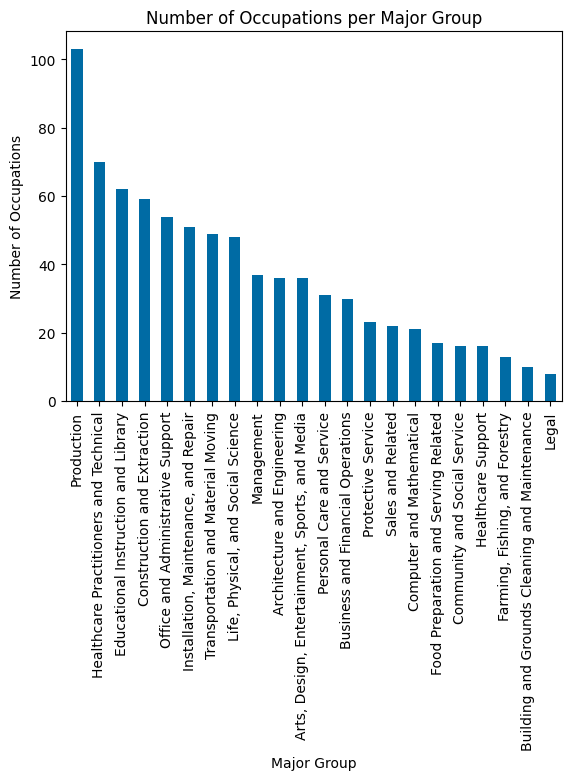

In [ ]:
#How many occupations are in each major group?
ai_jobs['Major Group'].value_counts().plot(kind='bar')

plt.title('Number of Occupations per Major Group')
plt.xlabel('Major Group')
plt.ylabel('Number of Occupations')
plt.show()

Vertical bar chart titled "Number of Occupations per Major Group" which shows the count of occupations across 22 major groups, arranged in descending order from Production (103) down to Legal (8).

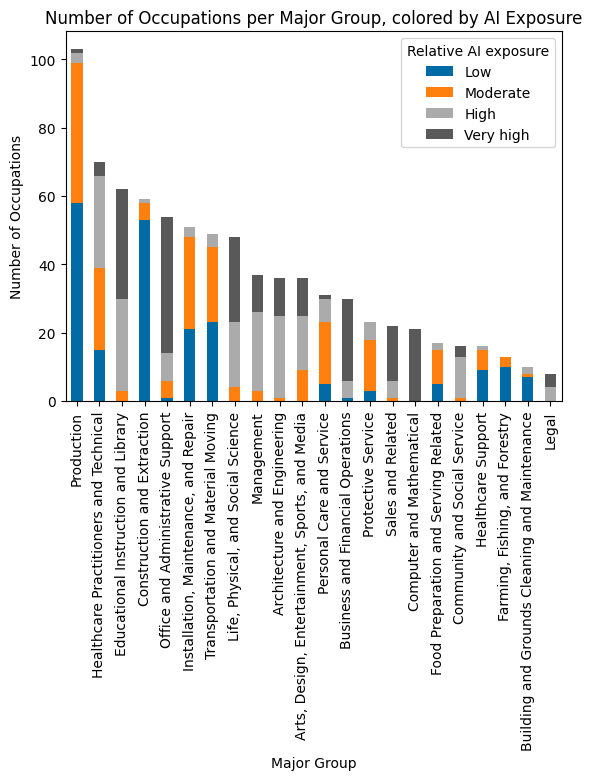

In [ ]:
#What is the distribution of AI exposure categories across major groups?
auxiliary_df = (
    ai_jobs.groupby(['Major Group', 'Relative AI exposure'])
    .size()
)

auxiliary_df = auxiliary_df.unstack(fill_value=0)
auxiliary_df = auxiliary_df[['Low', 'Moderate', 'High', 'Very high']]

auxiliary_df = auxiliary_df.loc[
    auxiliary_df.sum(axis=1).sort_values(ascending=False).index
]

auxiliary_df.plot.bar(stacked=True)
plt.title('Number of Occupations per Major Group, colored by AI Exposure')
plt.xlabel('Major Group')
plt.ylabel('Number of Occupations')
plt.style.use('tableau-colorblind10')
plt.show()

Same vertical bar chart, but including stacked bars colored by AI Exposure.

**Summary Statistics:**

In [ ]:
jobs_demographic = pd.read_csv('joint_demographic_soc.csv', keep_default_na=False)
jobs_demographic.describe() #Table of summary statistics

,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Women,White,Black or African American,Asian,Hispanic or Latino
count,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.000000,268.0000
mean,431.763806,445.004104,13.240672,3.184328,44.477612,70268.992537,48.148507,75.914179,12.611940,7.442164,18.5250
std,651.375271,665.181953,42.951788,7.038597,87.100813,32773.334165,27.896100,9.490777,7.361663,7.267132,10.3102
min,21.900000,22.900000,-200.600000,-34.400000,1.100000,31200.000000,0.600000,25.100000,0.000000,0.000000,3.5000
25%,96.800000,99.425000,0.275000,0.200000,7.675000,45927.500000,22.725000,71.275000,7.475000,3.700000,11.8750
50%,187.300000,200.150000,5.750000,3.800000,16.200000,60705.000000,50.600000,76.550000,11.200000,5.650000,16.0500
75%,437.525000,463.150000,17.825000,6.250000,43.150000,82930.000000,73.425000,81.800000,16.425000,9.400000,21.6000
max,3998.100000,4079.100000,250.700000,41.000000,827.400000,213990.000000,100.000000,96.600000,43.500000,67.500000,66.0000


**Evaluating relationships between race and median annual wage**

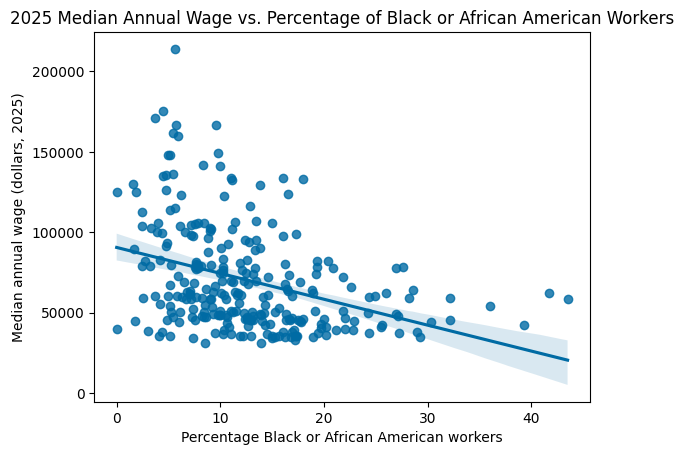

In [ ]:
#What is the relationship between the percentage of workers being Black and median annual wage?
sns.regplot(jobs_demographic,
            x= 'Black or African American',
            y = 'Median annual wage, dollars, 2025')

plt.title('2025 Median Annual Wage vs. Percentage of Black or African American Workers')
plt.xlabel('Percentage Black or African American workers')
plt.ylabel('Median annual wage (dollars, 2025)')
plt.show()

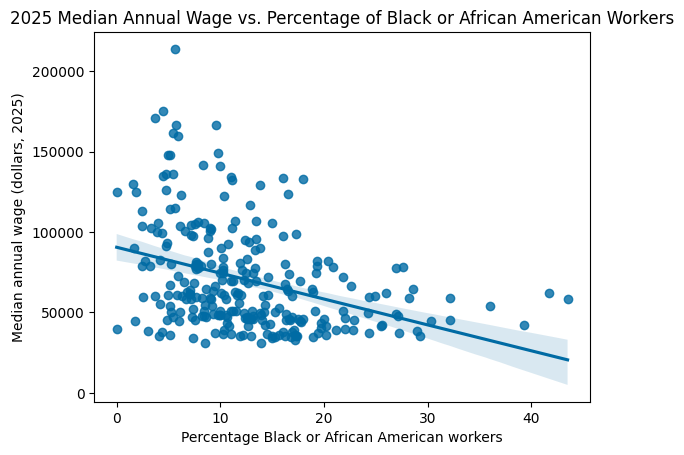

In [ ]:
#What is the relationship between the percentage of workers being Black and median annual wage?
sns.regplot(jobs_demographic,
            x= 'Black or African American',
            y = 'Median annual wage, dollars, 2025')

plt.title('2025 Median Annual Wage vs. Percentage of Black or African American Workers')
plt.xlabel('Percentage Black or African American workers')
plt.ylabel('Median annual wage (dollars, 2025)')
plt.show()

Scatterplot titled '2025 Median Annual Wage vs. Percentage of Black or African American Workers,' observations are clustered to the bottom left, with a slightly negative best fit line and large variability. General L-shape in the observations.

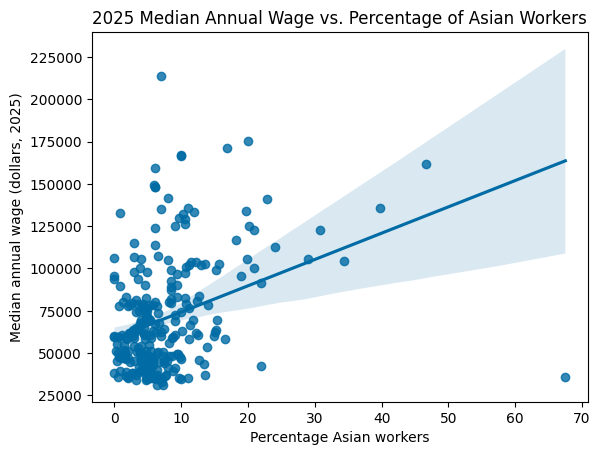

In [ ]:
#What is the relationship between the percentage of workers being Asian and median annual wage?
sns.regplot(jobs_demographic,
            x= 'Asian',
            y = 'Median annual wage, dollars, 2025')

plt.title('2025 Median Annual Wage vs. Percentage of Asian Workers')
plt.xlabel('Percentage Asian workers')
plt.ylabel('Median annual wage (dollars, 2025)')
plt.show()

Scatterplot titled '2025 Median Annual Wage vs. Percentage of Asian Workers,' observations are clustered to the bottom left, expanding outward, with a positive best fit line and large variability. No observable shapes or linear correlation.

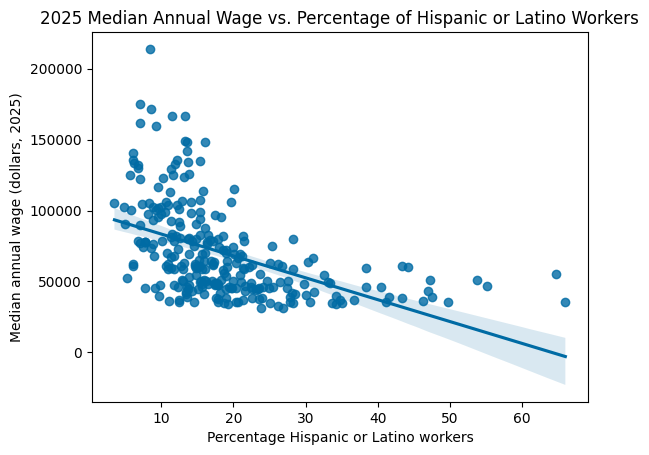

In [ ]:
#What is the relationship between the percentage of workers being Hispanic or Latino and median annual wage?
sns.regplot(jobs_demographic,
            x= 'Hispanic or Latino',
            y = 'Median annual wage, dollars, 2025')

plt.title('2025 Median Annual Wage vs. Percentage of Hispanic or Latino Workers')
plt.xlabel('Percentage Hispanic or Latino workers')
plt.ylabel('Median annual wage (dollars, 2025)')
plt.show()

Scatterplot titled '2025 Median Annual Wage vs. Percentage of Hispanic or Latino Workers,' observations are clustered to the bottom left, with a negative best fit line and general L-shape.

**Evaluating relationship between gender and AI exposure**

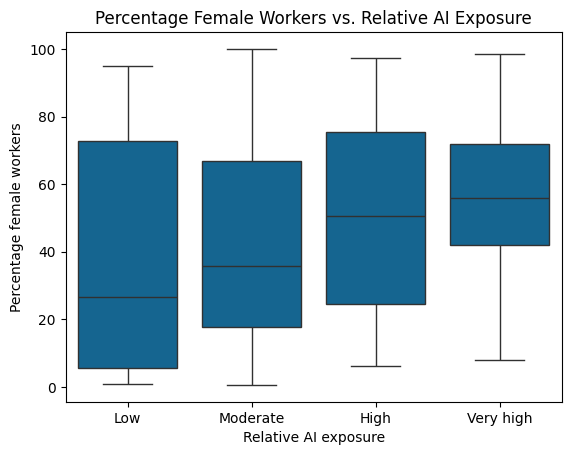

In [ ]:
#What is the relationship between sex and relative AI exposure?
# We were curious whether BLS may predict that female-dominated occupations
# are more or less exposed to AI compared to male-dominated fields
sns.boxplot(jobs_demographic,
            x= 'Relative AI exposure',
            y = 'Women',
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Percentage Female Workers vs. Relative AI Exposure')
plt.xlabel('Relative AI exposure')
plt.ylabel('Percentage female workers')
plt.show()

Boxplot titled Percentage Female Workers vs. Relative AI Exposure. Boxes grouped by AI Exposure, labeled "Low", "Moderate", "High", and "Very High".


In [ ]:
# Significant difference in percent female workers across AI exposure groups,
# such that higher AI exposure is correlated with higher percentage female workers.

female_ai = ols('Women ~ Q("Relative AI exposure")', data=demo_df).fit()
female_ai_table = sm.stats.anova_lm(female_ai)
print(female_ai_table)

                              df         sum_sq      mean_sq         F  \
Q("Relative AI exposure")    3.0   10778.555767  3592.851922  4.858096   
Residual                   267.0  197462.423864   739.559640       NaN   

                             PR(>F)  
Q("Relative AI exposure")  0.002624  
Residual                        NaN  


**Evaluating relationship between gender and projected change in employment from 2025-35**

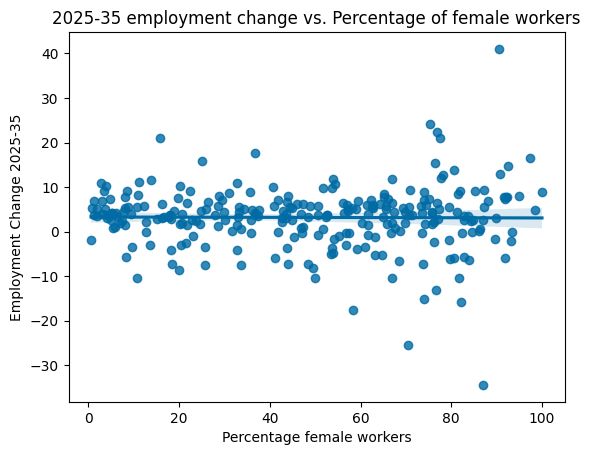

In [ ]:
#What is the relationship between sex and projected change in employment from 2025-35?
# similarly, we were curious whether BLS may predict female-dominated jobs
# will grow or decline more or less than male-dominated
sns.regplot(jobs_demographic,
            x= 'Women',
            y = 'Employment change, percent, 2025–35')

plt.title('2025-35 employment change vs. Percentage of female workers')
plt.xlabel('Percentage female workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 Employment Change  vs. Percentage of female workers.' X axis is Percentage of female workers. Y axis is Employment Change 2025-35. Observations are clustered at the midpoint of 0% changes of employment. There is high variability in percentage of female workers.


**Evaluating relationships between race and AI exposure**

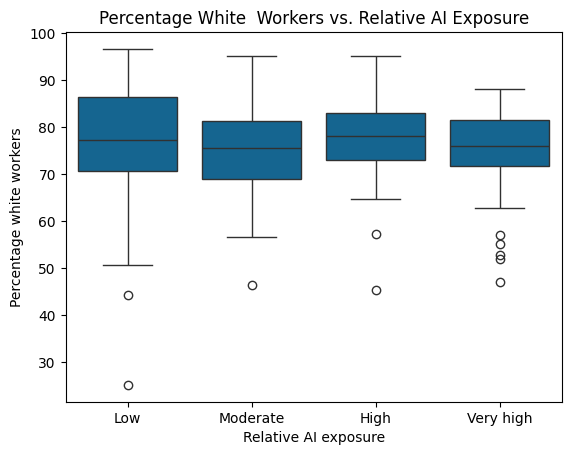

In [ ]:
#What is the relationship between race and relative AI exposure?
# We were curious whether BLS may predict that white-dominated occupations
# are more or less exposed to AI compared to lesser dominated fields
sns.boxplot(demo_df,
            x= 'Relative AI exposure',
            y = 'White',
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Percentage White  Workers vs. Relative AI Exposure')
plt.xlabel('Relative AI exposure')
plt.ylabel('Percentage white workers')
plt.show()

In [ ]:
# No significant difference in percent white workers across AI exposure groups

white_ai = ols('White ~ Q("Relative AI exposure")', data=demo_df).fit()
white_ai_table = sm.stats.anova_lm(white_ai)
print(white_ai_table)

                              df        sum_sq     mean_sq         F    PR(>F)
Q("Relative AI exposure")    3.0    303.003475  101.001158  1.111389  0.344909
Residual                   267.0  24264.515270   90.878334       NaN       NaN


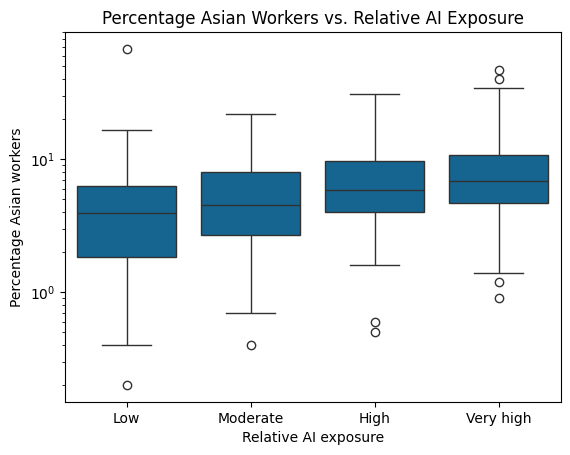

In [ ]:
sns.boxplot(demo_df,
            x= 'Relative AI exposure',
            y = 'Asian',
            log_scale = True,
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Percentage Asian Workers vs. Relative AI Exposure')
plt.xlabel('Relative AI exposure')
plt.ylabel('Percentage Asian workers')
plt.show()

In [ ]:
# Significant difference in percent Asian workers across AI exposure groups,
# such that higher AI exposure is correlated with higher percentage Asian workers.

asian_ai = ols('Asian ~ Q("Relative AI exposure")', data=demo_df).fit()
asian_ai_table = sm.stats.anova_lm(asian_ai)
print(asian_ai_table)

                              df        sum_sq     mean_sq        F   PR(>F)
Q("Relative AI exposure")    3.0    601.892303  200.630768  3.93069  0.00905
Residual                   267.0  13628.246442   51.042122      NaN      NaN


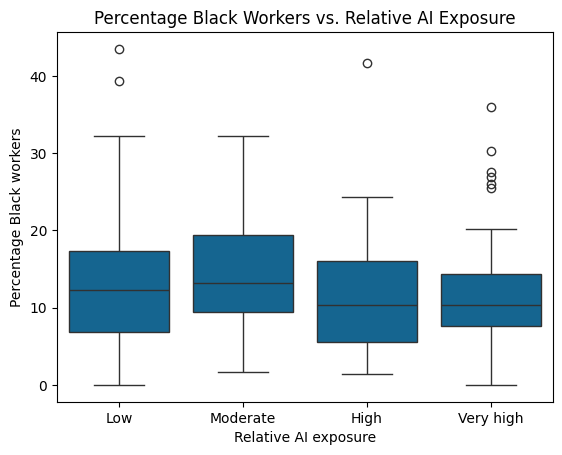

In [ ]:
sns.boxplot(demo_df,
            x= 'Relative AI exposure',
            y = 'Black or African American',
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Percentage Black Workers vs. Relative AI Exposure')
plt.xlabel('Relative AI exposure')
plt.ylabel('Percentage Black workers')
plt.show()

In [ ]:
# Significant difference in percent Black workers across AI exposure groups

black_ai = ols('Q("Black or African American") ~ Q("Relative AI exposure")', data=demo_df).fit()
black_ai_table = sm.stats.anova_lm(black_ai)
print(black_ai_table)

                              df        sum_sq     mean_sq         F    PR(>F)
Q("Relative AI exposure")    3.0    572.850127  190.950042  3.632155  0.013464
Residual                   267.0  14036.753415   52.572110       NaN       NaN


In [ ]:
# The mean percent Black workers is significantly higher for jobs with Moderate
# AI exposure compared to High or Very High AI Exposure. It is not significantly
# higher than that of Low AI Exposure.

sp.posthoc_ttest(demo_df, val_col='Black or African American', group_col='Relative AI exposure', p_adjust='holm')

,Very high,High,Moderate,Low
Very high,1.000000,0.877041,0.025705,0.463529
High,0.877041,1.000000,0.025705,0.452292
Moderate,0.025705,0.025705,1.000000,0.877041
Low,0.463529,0.452292,0.877041,1.000000


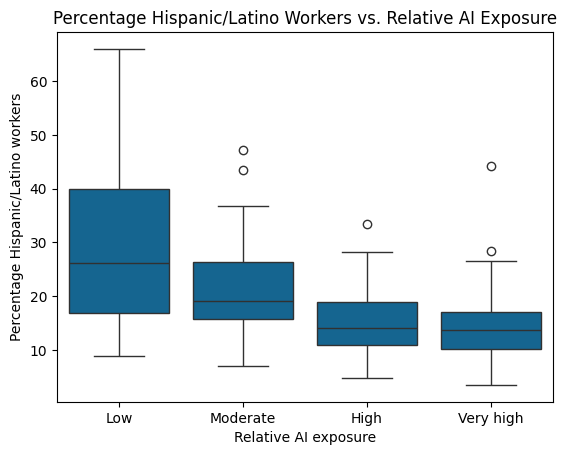

In [ ]:
sns.boxplot(demo_df,
            x= 'Relative AI exposure',
            y = 'Hispanic or Latino',
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Percentage Hispanic/Latino Workers vs. Relative AI Exposure')
plt.xlabel('Relative AI exposure')
plt.ylabel('Percentage Hispanic/Latino workers')
plt.show()

In [ ]:
# Highly significant relationship between percent of Hispanic workers and
# AI Exposure, such that greater exposure is correlated with a lower percent

hisp_ai = ols('Q("Hispanic or Latino") ~ Q("Relative AI exposure")', data=demo_df).fit()
hisp_ai_table = sm.stats.anova_lm(hisp_ai)
print(hisp_ai_table)

                              df        sum_sq      mean_sq          F  \
Q("Relative AI exposure")    3.0   7966.762016  2655.587339  34.343123   
Residual                   267.0  20645.816508    77.325155        NaN   

                                 PR(>F)  
Q("Relative AI exposure")  8.367999e-19  
Residual                            NaN  


**Evaluating relationships between race and projected change in employment from 2025-35**

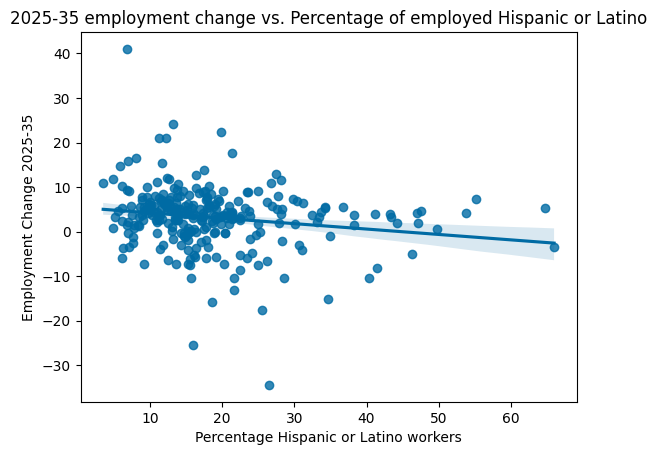

In [ ]:
#What is the relationship between the projected change in employment from 2025-35 and workers who are Hispanic or Latino?
# A similar question based on jobs with a larger Hispanic/Latino population

sns.regplot(jobs_demographic,
            x= 'Hispanic or Latino',
            y = 'Employment change, percent, 2025–35')

plt.title('2025-35 employment change vs. Percentage of employed Hispanic or Latino')
plt.xlabel('Percentage Hispanic or Latino workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 Employment Change  vs. Percentage of Hispanic or Latino workers.'X axis is Percentage of Hispanic or Latino workers. Y axis is Employment Change 2025-35.  Observations are clustered around 10-20%, with a slightly negative slope in change in employment.  


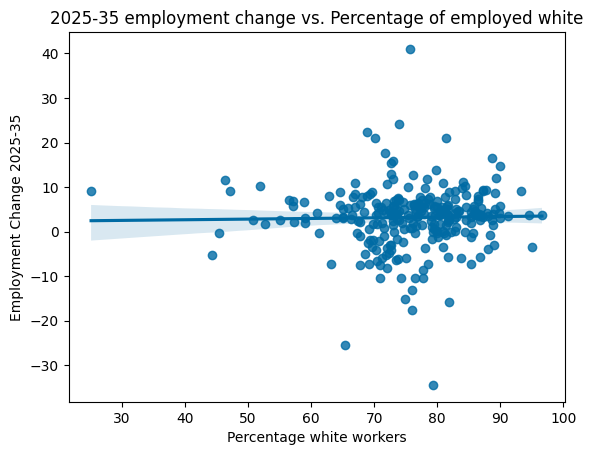

In [ ]:
#What is the relationship between the projected change in employment from 2025-35 and workers who are white?
# A similar question based on jobs which are more predominantly white
sns.regplot(jobs_demographic,
            x= 'White',
            y = 'Employment change, percent, 2025–35')

plt.title('2025-35 employment change vs. Percentage of employed white')
plt.xlabel('Percentage white workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 Employment Change  vs. Percentage of White workers.' X axis is Percentage of white workers. Y axis is Employment Change 2025-35.  Observations are clustered around 70-90%, with no change in employment.


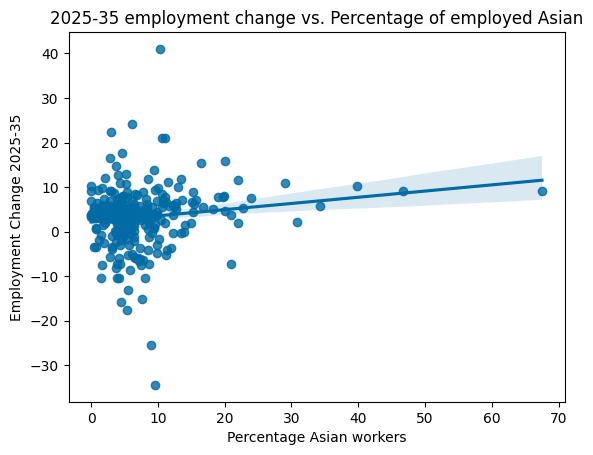

In [ ]:
#What is the relationship between the projected change in employment from 2025-35 and workers who are Asian?
# A similar question based on jobs with a larger Asian population
sns.regplot(jobs_demographic,
            x= 'Asian',
            y = 'Employment change, percent, 2025–35')

plt.title('2025-35 employment change vs. Percentage of employed Asian')
plt.xlabel('Percentage Asian workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

Scatterplot titled '2025-35 Employment Change vs. Percentage of Asian workers.' X axis is Percentage of white workers. Y axis is Employment Change 2025-35. Observations are clustered around 0-10%, with a slight positive line of best fit.

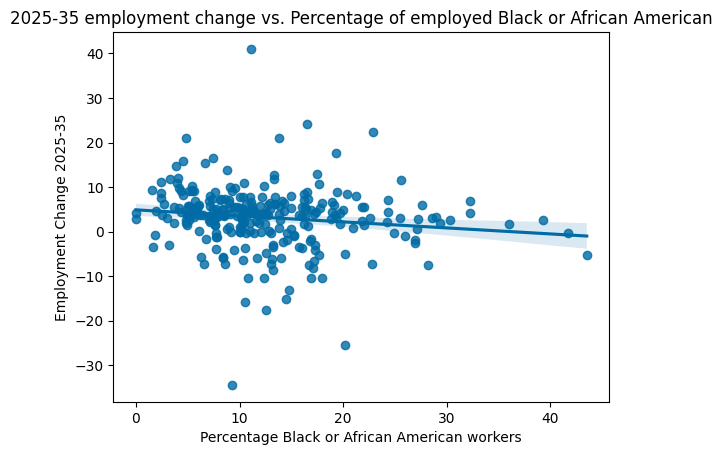

In [ ]:
#What is the relationship between the projected change in employment from 2025-35 and workers who are Black?
# A similar question based on jobs with a larger Black population
sns.regplot(jobs_demographic,
            x= 'Black or African American',
            y = 'Employment change, percent, 2025–35')

plt.title('2025-35 employment change vs. Percentage of employed Black or African American')
plt.xlabel('Percentage Black or African American workers')
plt.ylabel('Employment Change 2025-35')
plt.show()

This is a scatter plot with a linear regression line titled “2025-35 employment change vs. Percentage of employed Black or African American.” The x-axis is labelled “Percentage of Black or African American workers,” ranging from 0 to 45 and the y-axis is labelled “Employment Change 2025-35” ranging from -30 to 40, which represents percentage change. Most of the data is concentrated between 5 and 20 on the x axis and -10 and 10 on the y-axis. There is a slight negative slope.


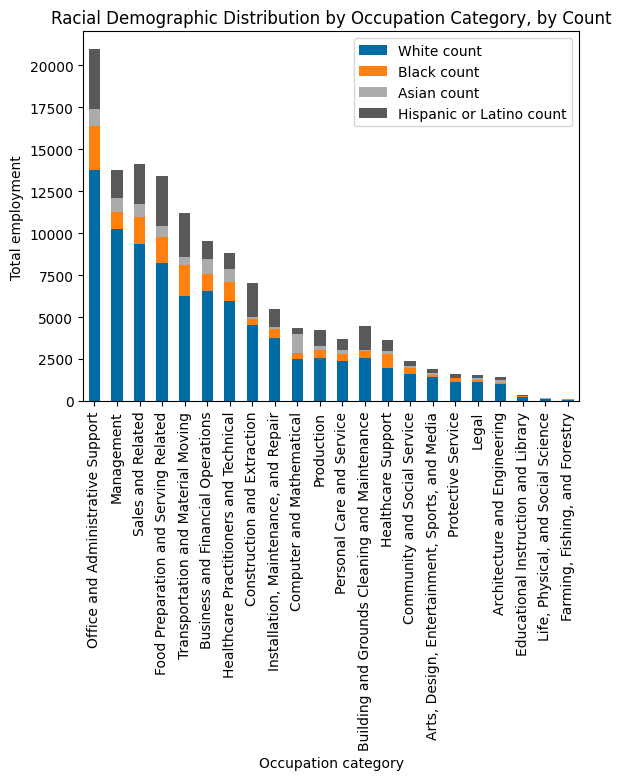

In [ ]:
#What is the distribution of racial demographics across major occupation groups?
jobs_copy = jobs_demographic.copy()
jobs_copy['White count'] = jobs_copy['Employment, 2025'] * (jobs_copy['White']/100)
jobs_copy['Black count'] = jobs_copy['Employment, 2025'] * (jobs_copy['Black or African American']/100)
jobs_copy['Asian count'] = jobs_copy['Employment, 2025'] * (jobs_copy['Asian']/100)
jobs_copy['Hispanic or Latino count'] = jobs_copy['Employment, 2025'] * (jobs_copy['Hispanic or Latino']/100)

grouped_sums = jobs_copy.groupby('Major Group')[
    ['Employment, 2025', 'White count', 'Black count', 'Asian count', 'Hispanic or Latino count']
].sum()

grouped_sums = grouped_sums.sort_values(by='Employment, 2025', ascending=False)

grouped_sums_without_total = grouped_sums.drop(columns='Employment, 2025')

grouped_sums_without_total.plot(kind='bar', stacked=True)
plt.title('Racial Demographic Distribution by Occupation Category, by Count')
plt.xlabel('Occupation category')
plt.ylabel('Total employment')
plt.show()



This is a vertical bar chart titled "Racial Demographic Distribution by Occupation Category, by Count" displaying total employment counts across 22 occupation categories. It is  Each  bar is broken down into four racial/ethnic demogrpahic counts, with White represented by the color blue, Black represented by Orange, Asian by light grey, and Hispanic or Latino by dark grey.


**Relationship between education and AI exposure**

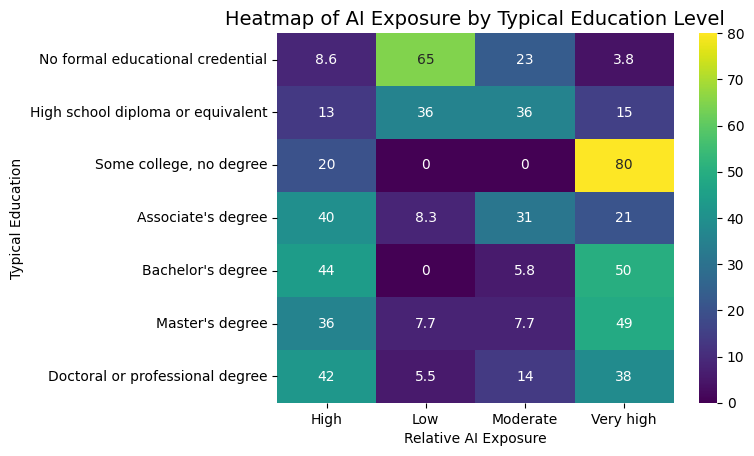

In [ ]:
# What is the relationship between typical level of education required and relative AI exposure?
# We were curious whether the BLS predicts greater AI exposure for different
# levels of education
edu_ai_pct = (
    pd.crosstab(
        ai_jobs['Typical education'],
        ai_jobs['Relative AI exposure'],
        normalize='index',
    )* 100
)
education_order = [
    'No formal educational credential',
    'High school diploma or equivalent',
    'Some college, no degree',
    'Associate\'s degree',
    'Bachelor\'s degree',
    'Master\'s degree',
    'Doctoral or professional degree'
]

edu_ai_pct = edu_ai_pct.reindex(education_order)

sns.heatmap(edu_ai_pct, annot=True, cmap='viridis')
plt.title('Heatmap of AI Exposure by Typical Education Level', fontsize=14)
plt.xlabel('Relative AI Exposure')
plt.ylabel('Typical Education')
plt.show()

Annotated heat map titled "heatmap of AI Exposure by typical Education Level" displaying percentages of occupations across 7 education levels mapped against the four levels of Relative Ai Exposure: High, Loqwe, Moderate, and Very high.  

**Relationship between training and AI exposure**

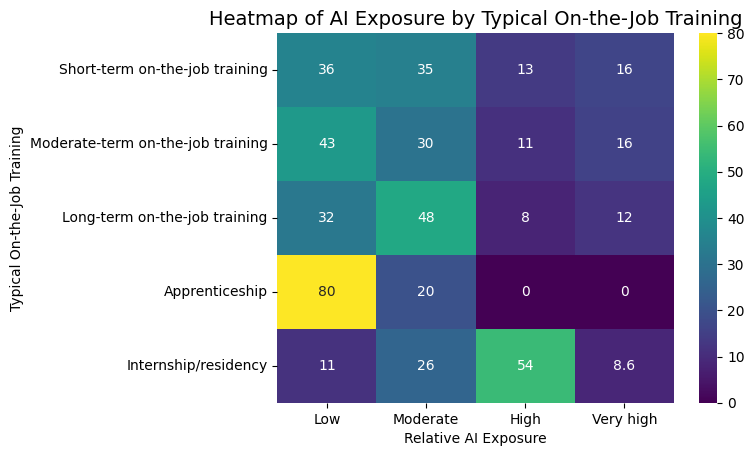

In [ ]:
# What is the relationship between level of typical on-the-job training required and relative AI exposure?
# Similarly, we wanted to see if BLS predicts greater AI exposure for different
# levels of on the job training
training_ai_pct = (
    pd.crosstab(
        ai_jobs['Typical on-the-job training'],
        ai_jobs['Relative AI exposure'],
        normalize='index',
    )* 100
)
training_order = [
    'Short-term on-the-job training',
    'Moderate-term on-the-job training',
    'Long-term on-the-job training',
    'Apprenticeship',
    'Internship/residency',
]

ai_exposure_order = [
    'Low',
    'Moderate',
    'High',
    'Very high'
]

training_ai_pct = training_ai_pct.reindex(training_order) #Order training levels
training_ai_pct = training_ai_pct[ai_exposure_order] #Order AI exposure categories

sns.heatmap(training_ai_pct, annot=True, cmap='viridis')
plt.title('Heatmap of AI Exposure by Typical On-the-Job Training', fontsize=14)
plt.xlabel('Relative AI Exposure')
plt.ylabel('Typical On-the-Job Training')
plt.show()

**Exploring the relationship between AI Exposure and other employment variables**

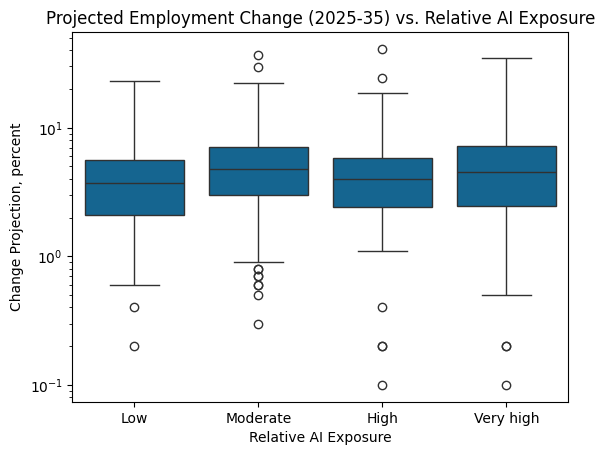

In [ ]:
# What is the relationship between Relative AI exposure and Employment change, percent?
# This was one of our main research questions - we wanted to see if the BLS
# predicts that AI exposure will have an impact on 2035 employment
sns.boxplot(ai_jobs,
            x= 'Relative AI exposure',
            y = 'Employment change, percent, 2025–35',
            log_scale = True,
            order = ['Low','Moderate', 'High', 'Very high'])

plt.title('Projected Employment Change (2025-35) vs. Relative AI Exposure')
plt.ylabel("Change Projection, percent")
plt.xlabel("Relative AI Exposure")

plt.show()

In [ ]:
# Highly significant difference in projected employment change percent across AI
# exposure categories

employment_ai = ols('Q("Employment change, percent, 2025–35") ~ Q("Relative AI exposure")', data=ai_jobs).fit()
employment_ai_table = sm.stats.anova_lm(employment_ai)
print(employment_ai_table)

                              df        sum_sq     mean_sq         F    PR(>F)
Q("Relative AI exposure")    3.0   1105.662728  368.554243  7.130825  0.000099
Residual                   808.0  41761.204070   51.684659       NaN       NaN


In [ ]:
ai_jobs.groupby("Relative AI exposure")["Employment change, percent, 2025–35"].mean()

,"Employment change, percent, 2025–35"
Relative AI exposure,
High,3.295455
Low,0.211848
Moderate,2.706533
Very high,2.022549


In [ ]:
# Moderate and High AI exposure jobs have significantly different projected
# percent change compared to Low AI exposure, such that Low AI jobs
# shows the lowest projected growth

sp.posthoc_ttest(ai_jobs, val_col='Employment change, percent, 2025–35', group_col='Relative AI exposure', p_adjust='holm')

,Very high,High,Moderate,Low
Very high,1.000000,0.212739,0.736720,0.058948
High,0.212739,1.000000,0.736720,0.000030
Moderate,0.736720,0.736720,1.000000,0.003144
Low,0.058948,0.000030,0.003144,1.000000


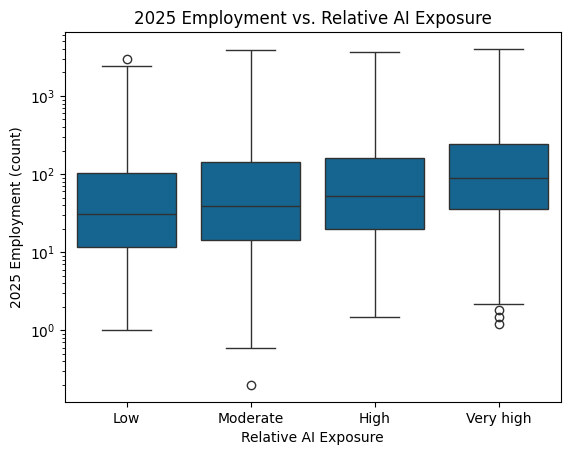

In [ ]:
#What is the relationship between Relative AI exposure and Employment counts in 2025?
# We wanted to see how different levels of AI exposure are represented in
# current employment
sns.boxplot(ai_jobs, x= 'Relative AI exposure', y = 'Employment, 2025', log_scale = True, order = ['Low','Moderate', 'High', 'Very high'])

plt.title('2025 Employment vs. Relative AI Exposure')
plt.ylabel("2025 Employment (count)")
plt.xlabel("Relative AI Exposure")

plt.show()

In [ ]:
# No significance for difference in current employment by AI exposure, there are
# currently roughly the same amount of occupations in each category

employment25_ai = ols('Q("Employment, 2025") ~ Q("Relative AI exposure")', data=ai_jobs).fit()
employment25_ai_table = sm.stats.anova_lm(employment25_ai)
print(employment25_ai_table)

                              df        sum_sq        mean_sq        F  \
Q("Relative AI exposure")    3.0  1.379702e+06  459900.700235  2.34066   
Residual                   808.0  1.587585e+08  196483.341666      NaN   

                             PR(>F)  
Q("Relative AI exposure")  0.072027  
Residual                        NaN  


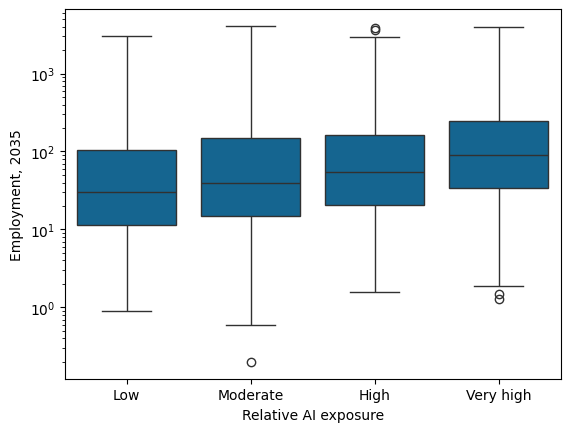

In [ ]:
#What is the relationship between Relative AI exposure and projected 2035 employment counts?
# Similarly, we wanted to see how different levels of AI exposure are projected
# by BLS to be represented in 2035
sns.boxplot(ai_jobs, x= 'Relative AI exposure', y = 'Employment, 2035', log_scale = True, order = ['Low','Moderate', 'High', 'Very high'])
plt.show()

In [ ]:
# Also no significance for difference in projected employment counts by AI exposure,
# they predict there will remain the same amount of occupations in each category

employment35_ai = ols('Q("Employment, 2035") ~ Q("Relative AI exposure")', data=ai_jobs).fit()
employment35_ai_table = sm.stats.anova_lm(employment35_ai)
print(employment35_ai_table)

                              df        sum_sq        mean_sq         F  \
Q("Relative AI exposure")    3.0  1.403225e+06  467741.810308  2.268706   
Residual                   808.0  1.665863e+08  206171.199747       NaN   

                             PR(>F)  
Q("Relative AI exposure")  0.079187  
Residual                        NaN  


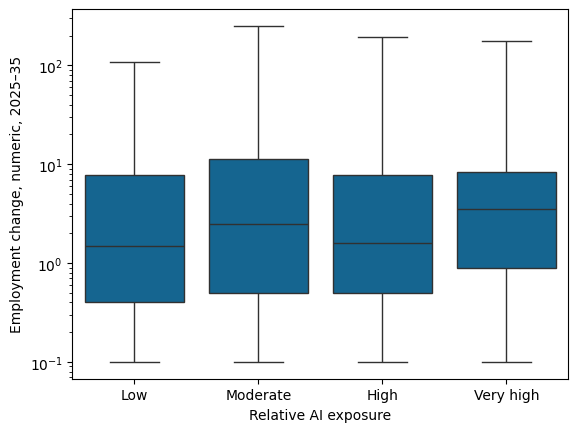

In [ ]:
#What is the relationship between Relative AI exposure and numeric employment change between 2025 and 2035?
# This also speaks to our research question - does the BLS predict that AI
# exposure category will play a role in the amount of new/lost jobs in an
# occupation?
sns.boxplot(ai_jobs, x= 'Relative AI exposure', y = 'Employment change, numeric, 2025–35', log_scale = True, order = ['Low','Moderate', 'High', 'Very high'])
plt.show()

In [ ]:
# Also no significant difference in projected numeric change in occupation
# across different AI exposure, again suggesting that number of jobs will
# not be affected by AI exposure in BLS eyes

count_ai = ols('Q("Employment change, numeric, 2025–35") ~ Q("Relative AI exposure")', data=ai_jobs).fit()
count_ai_table = sm.stats.anova_lm(count_ai)
print(count_ai_table)

                              df         sum_sq      mean_sq         F  \
Q("Relative AI exposure")    3.0    3824.693494  1274.897831  1.755818   
Residual                   808.0  586687.938563   726.098934       NaN   

                             PR(>F)  
Q("Relative AI exposure")  0.154141  
Residual                        NaN  


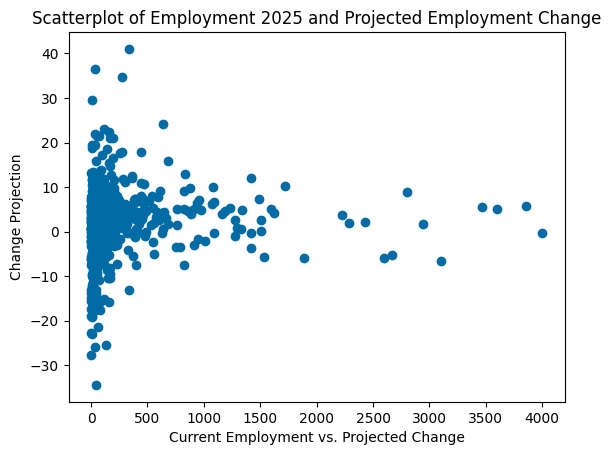

In [ ]:
#What is the relationship between current employment (2025) and projected percent change in employment
# We wanted to visualize how current employment may impact projected employment change percent
plt.scatter(x=ai_jobs['Employment, 2025'], y= ai_jobs['Employment change, percent, 2025–35'])
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

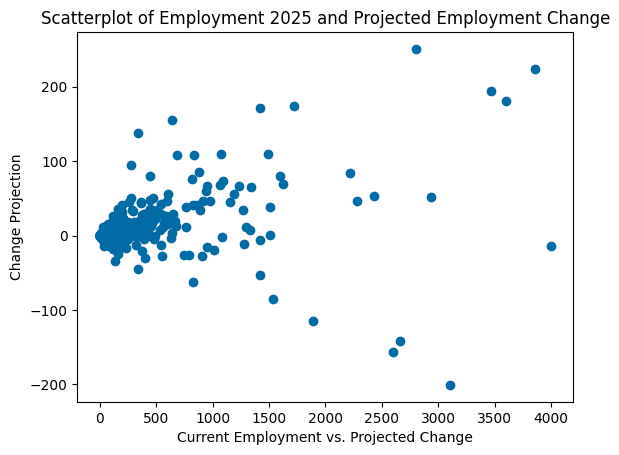

In [ ]:
#What is the relationship between current employment (2025) and projected numeric change in employment
# Similarly, we wanted to visualize how curret employment may impact projected numeric
# employment change
plt.scatter(x=ai_jobs['Employment, 2025'], y= ai_jobs['Employment change, numeric, 2025–35'])
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

In [ ]:
# We wanted to look into differences among different AI exposure groups,
# So we split into 4 dataframes of low, moderate, high, and very high exposure
ai_low = ai_jobs[ai_jobs['Relative AI exposure'] == 'Low']

In [ ]:
ai_mod = ai_jobs[ai_jobs['Relative AI exposure'] == 'Moderate']

In [ ]:
ai_high = ai_jobs[ai_jobs['Relative AI exposure'] == 'High']

In [ ]:
ai_vhigh = ai_jobs[ai_jobs['Relative AI exposure'] == 'Very high']

In [ ]:
np.mean(ai_low['Employment change, percent, 2025–35']),\
np.mean(ai_mod['Employment change, percent, 2025–35']),\
np.mean(ai_high['Employment change, percent, 2025–35']),\
np.mean(ai_vhigh['Employment change, percent, 2025–35'])

(np.float64(0.21184834123222743),
 np.float64(2.706532663316583),
 np.float64(3.2954545454545454),
 np.float64(2.022549019607843))

In [ ]:
# Similarly, we split into lower (low and moderate) and higher (high and very high)
# AI exposure. This similarly allowed us to analyze different levels of AI
# exposure, but this allows for larger sample sizes
ai_lower = ai_jobs[ai_jobs['Relative AI exposure'].isin(['Low', 'Moderate'])]

In [ ]:
ai_higher = ai_jobs[ai_jobs['Relative AI exposure'].isin(['High', 'Very high'])]

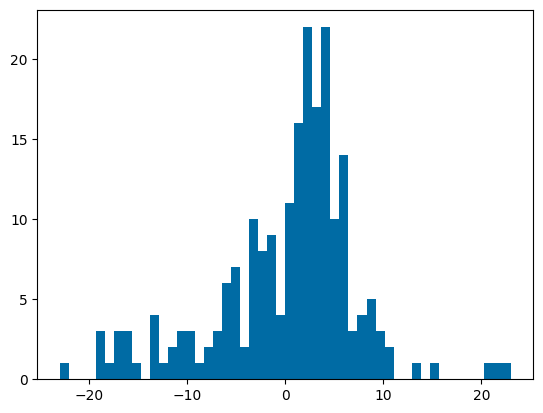

In [ ]:
# We were curious to see how distributions/standard deviations may differ across
# AI exposure categories. This may speak to certain demographics experiencing
# less change, or the BLS less intently projecting for certain groups
plt.hist(x=ai_low['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [ ]:
np.std(ai_low['Employment change, percent, 2025–35'])

7.222988701219705

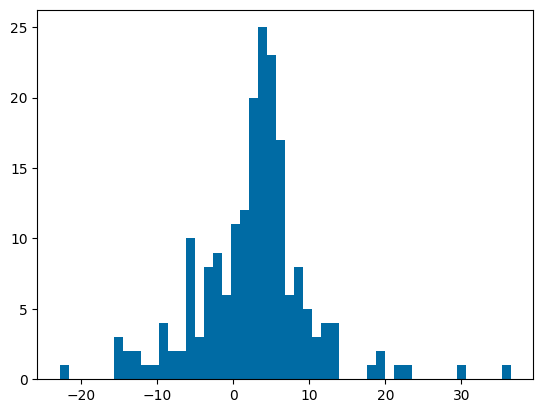

In [ ]:
plt.hist(x=ai_mod['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [ ]:
np.std(ai_mod['Employment change, percent, 2025–35'])

7.3989750436239

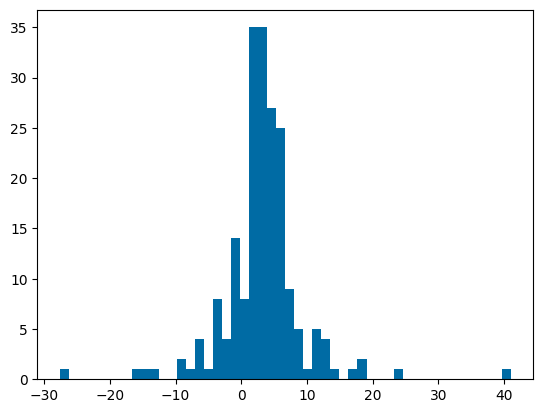

In [ ]:
plt.hist(x=ai_high['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [ ]:
np.std(ai_high['Employment change, percent, 2025–35'])

6.1346531473126396

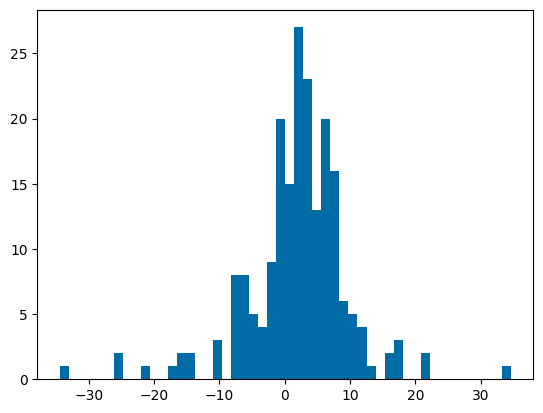

In [ ]:
plt.hist(x=ai_vhigh['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [ ]:
np.std(ai_vhigh['Employment change, percent, 2025–35'])

7.798710386889457

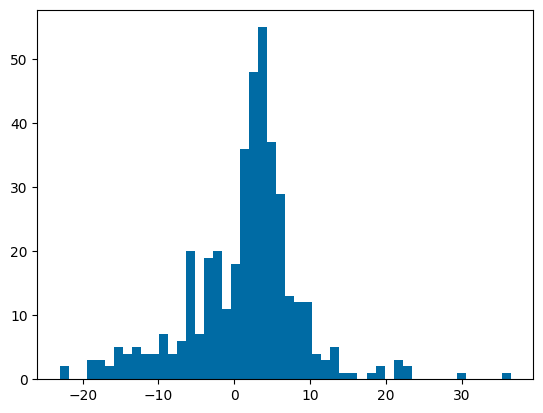

In [ ]:
plt.hist(x=ai_lower['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [ ]:
np.std(ai_lower['Employment change, percent, 2025–35'])

7.414517573698518

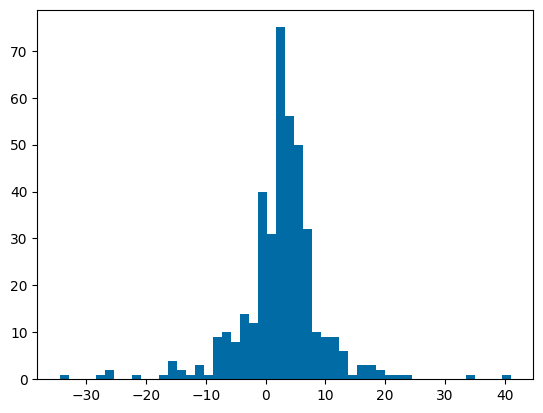

In [ ]:
plt.hist(x=ai_higher['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [ ]:
len(ai_lower)

410

In [ ]:
len(ai_higher)

402

In [ ]:
np.std(ai_lower['Employment change, percent, 2025–35'])

7.414517573698518

In [ ]:
np.std(ai_higher['Employment change, percent, 2025–35'])

7.057261335916835

In [ ]:
# Significant difference in variance between higher and lower AI exposure groups,
# such that lower has higher std, more uncertainty in jobs
from scipy import stats

stat, p_value = stats.levene(ai_higher['Employment change, percent, 2025–35'], ai_lower['Employment change, percent, 2025–35'], center='mean')

print(f"Levene Statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

Levene Statistic: 4.5038
P-value: 0.0341


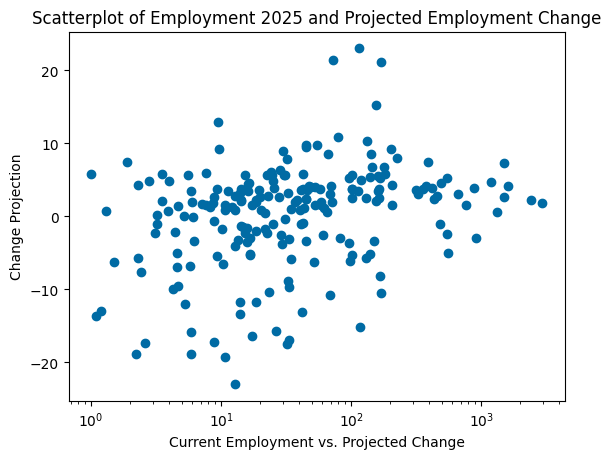

In [ ]:
# Next, we wanted to see how current employment change may predict employment
# change percent. This should not be a predictor, so if found to be significant
# it leads us to question the methods/projections of BLS

# we first looked at occupations with low relative AI exposure
plt.scatter(x=ai_low['Employment, 2025'], y= ai_low['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

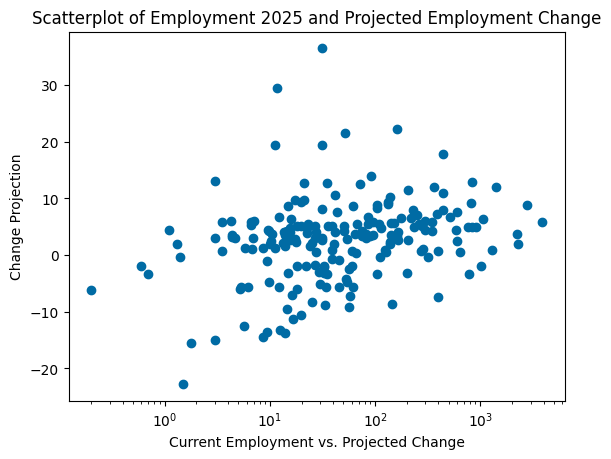

In [ ]:
# Same for moderate AI exposure

plt.scatter(x=ai_mod['Employment, 2025'], y= ai_mod['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

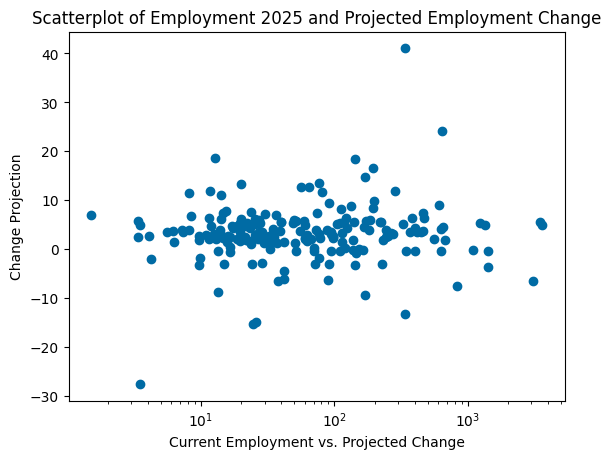

In [ ]:
# Same for high AI exposure

plt.scatter(x=ai_high['Employment, 2025'], y= ai_high['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

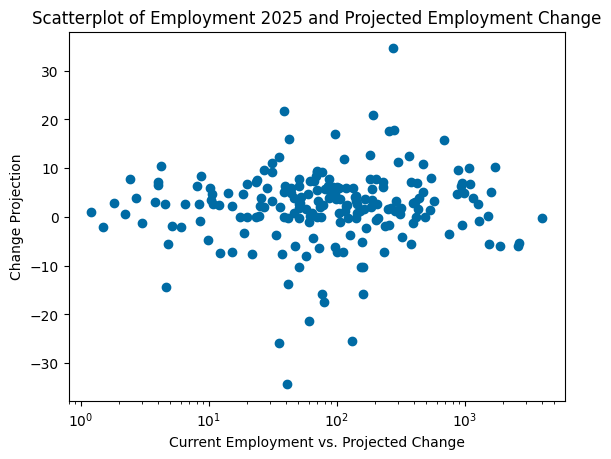

In [ ]:
# Same for very high AI exposure

plt.scatter(x=ai_vhigh['Employment, 2025'], y= ai_vhigh['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

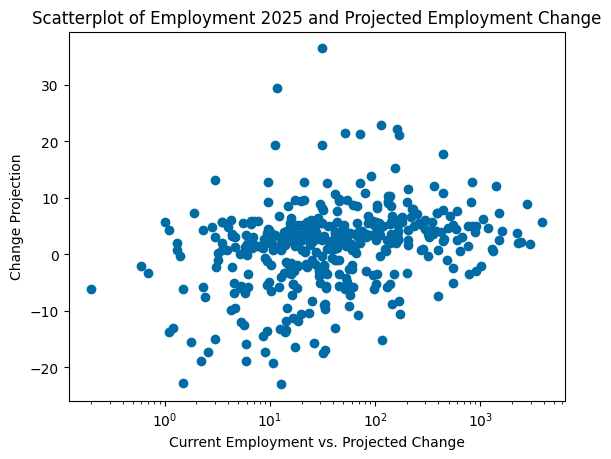

In [ ]:
# Same for lower AI exposure

plt.scatter(x=ai_lower['Employment, 2025'], y= ai_lower['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

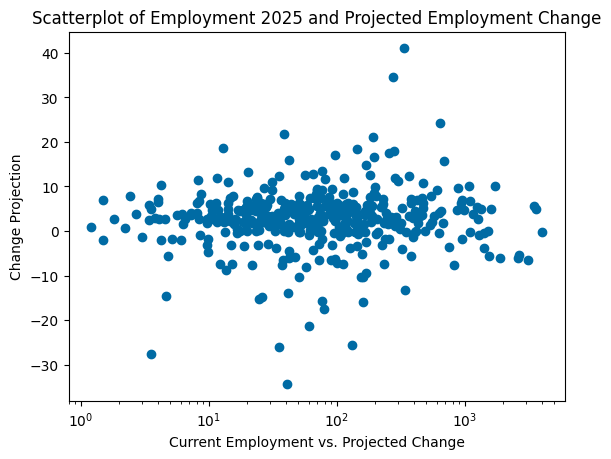

In [ ]:
# Same for higher AI exposure

plt.scatter(x=ai_higher['Employment, 2025'], y= ai_higher['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

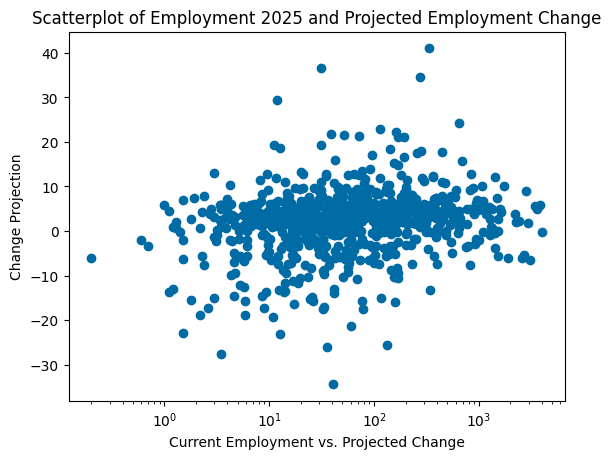

In [ ]:
# same with full df

plt.scatter(x=ai_jobs['Employment, 2025'], y= ai_jobs['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.title('Scatterplot of Employment 2025 and Projected Employment Change')
plt.ylabel("Change Projection")
plt.xlabel("Current Employment vs. Projected Change")
plt.show()

In [ ]:
# regression for the above relationships, starting with full dataframe
# current employment is significant predictor for percent change

X = np.log(ai_jobs['Employment, 2025'])
X = sm.add_constant(X)
y = ai_jobs['Employment change, percent, 2025–35']

model_employment = sm.OLS(y, X).fit()

model_employment.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     OLS Regression Results                                    
===============================================================================================
Dep. Variable:     Employment change, percent, 2025–35   R-squared:                       0.041
Model:                                             OLS   Adj. R-squared:                  0.040
Method:                                  Least Squares   F-statistic:                     34.51
Date:                                 Sat, 14 Nov 2026   Prob (F-statistic):           6.18e-09
Time:                                         04:30:12   Log-Likelihood:                -2745.6
No. Observations:                                  812   AIC:                             5495.
Df Residuals:                                      810   BIC:                             5505.
Df Model:                                            1                                         
Covariance Type:                             nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.4835      0.648     -2.289      0.022      -2.756      -0.211
Employment, 2025     0.8880      0.151      5.875      0.000       0.591       1.185
==============================================================================
Omnibus:                       88.145   Durbin-Watson:                   1.149
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              579.852
Skew:                          -0.197   Prob(JB):                    1.22e-126
Kurtosis:                       7.121   Cond. No.                         11.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# same for lower, employment is significant predictor for percent change

import statsmodels.api as sm

X = np.log(ai_lower['Employment, 2025'])
X = sm.add_constant(X)
y = ai_lower['Employment change, percent, 2025–35']

model_lower = sm.OLS(y, X).fit()

model_lower.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     OLS Regression Results                                    
===============================================================================================
Dep. Variable:     Employment change, percent, 2025–35   R-squared:                       0.089
Model:                                             OLS   Adj. R-squared:                  0.087
Method:                                  Least Squares   F-statistic:                     40.09
Date:                                 Sat, 14 Nov 2026   Prob (F-statistic):           6.40e-10
Time:                                         04:30:12   Log-Likelihood:                -1384.0
No. Observations:                                  410   AIC:                             2772.
Df Residuals:                                      408   BIC:                             2780.
Df Model:                                            1                                         
Covariance Type:                             nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -3.3805      0.836     -4.046      0.000      -5.023      -1.738
Employment, 2025     1.3091      0.207      6.332      0.000       0.903       1.716
==============================================================================
Omnibus:                       30.936   Durbin-Watson:                   1.361
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              118.429
Skew:                           0.125   Prob(JB):                     1.92e-26
Kurtosis:                       5.621   Cond. No.                         10.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# For higher AI exposure, employment is not a significant predictor for percent
# change. This may suggest projections for occupations with higher AI exposure
# rely more on typical reliable predictors used for projections

import statsmodels.api as sm

X = np.log(ai_higher['Employment, 2025'])
X = sm.add_constant(X)
y = ai_higher['Employment change, percent, 2025–35']

model_higher = sm.OLS(y, X).fit()

model_higher.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     OLS Regression Results                                    
===============================================================================================
Dep. Variable:     Employment change, percent, 2025–35   R-squared:                       0.004
Model:                                             OLS   Adj. R-squared:                  0.002
Method:                                  Least Squares   F-statistic:                     1.701
Date:                                 Sat, 14 Nov 2026   Prob (F-statistic):              0.193
Time:                                         04:30:12   Log-Likelihood:                -1355.1
No. Observations:                                  402   AIC:                             2714.
Df Residuals:                                      400   BIC:                             2722.
Df Model:                                            1                                         
Covariance Type:                             nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                1.3971      1.023      1.366      0.173      -0.613       3.408
Employment, 2025     0.2947      0.226      1.304      0.193      -0.149       0.739
==============================================================================
Omnibus:                       74.431   Durbin-Watson:                   1.005
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              729.444
Skew:                          -0.416   Prob(JB):                    4.01e-159
Kurtosis:                       9.546   Cond. No.                         13.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
category_change = ai_jobs.groupby('Major Group', as_index = False)[
    'Employment change, percent, 2025–35'].mean().sort_values('Employment change, percent, 2025–35')

In [ ]:
category_change

,Major Group,"Employment change, percent, 2025–35"
16,Office and Administrative Support,-6.024074
18,Production,-4.564078
20,Sales and Related,-1.477273
8,"Farming, Fishing, and Forestry",-0.961538
1,"Arts, Design, Entertainment, Sports, and Media",0.711111
6,Construction and Extraction,1.381356
19,Protective Service,1.430435
13,Legal,2.062500
7,Educational Instruction and Library,2.166129
21,Transportation and Material Moving,3.004082


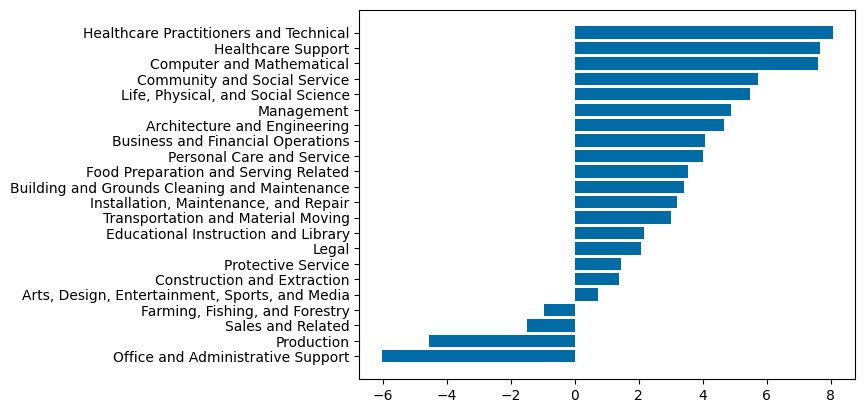

In [ ]:
# looking at projected change across categories, ranges from -6 to 8.

plt.barh(category_change['Major Group'], category_change['Employment change, percent, 2025–35'])
plt.show()

In [ ]:
# loading in BLS projections from past years for comparison

proj_2034 = pd.read_csv('bls_2024_occupations.csv')
proj_2033 = pd.read_csv('bls_2023_occupations.csv')
proj_2032 = pd.read_csv('bls_2022_occupations.csv')

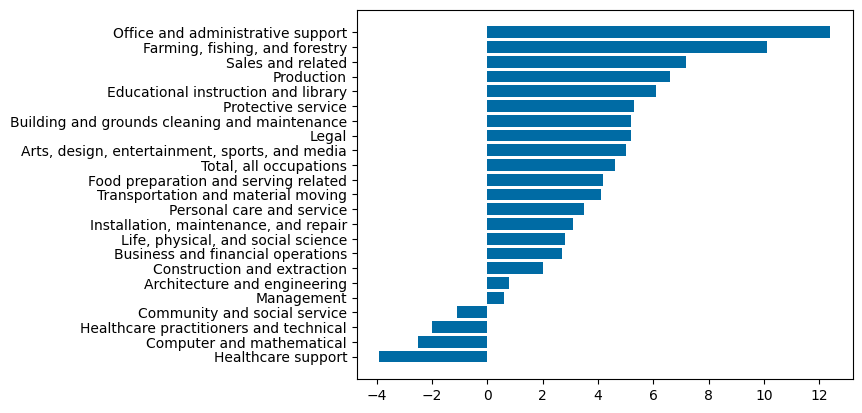

In [ ]:
# projected change from 2024-2034, made in 2024

plt.barh(proj_2034['Occupation'], proj_2034['Percent change, 2024–34'].sort_values())
plt.show()

In [ ]:
proj_2033 = proj_2033.dropna()

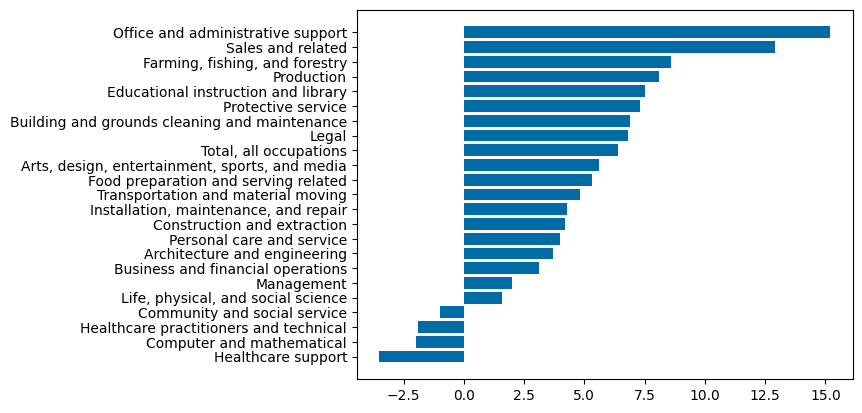

In [ ]:
# projected change from 2023-2033, made in 2023

plt.barh(proj_2033['Occupation'], proj_2033['Percent change, 2023–33'].sort_values())
plt.show()

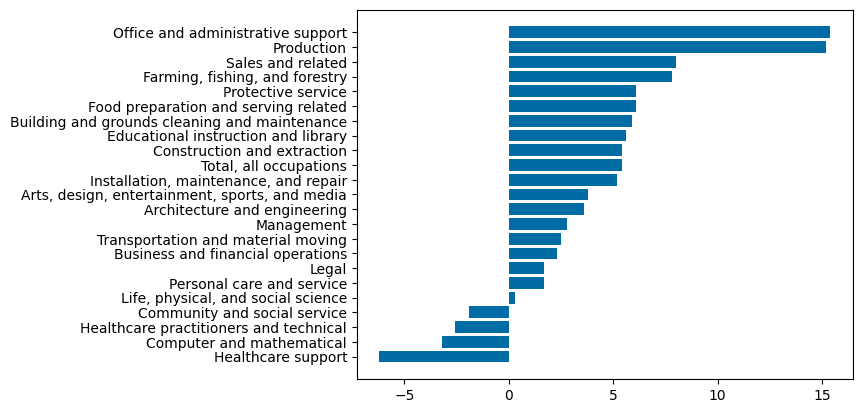

In [ ]:
# projected change from 2022-2032, made in 2022. 2025-35 projection shows
# lowest maximum growth

plt.barh(proj_2032['Occupation'], proj_2032['Percent change, 2022–32'].sort_values())
plt.show()

In [ ]:
np.std(category_change['Employment change, percent, 2025–35'])

3.5372238926483535

In [ ]:
np.std(proj_2034['Percent change, 2024–34'])

3.773316923466002

In [ ]:
np.std(proj_2033['Percent change, 2023–33'])

4.381676919582187

In [ ]:
np.std(proj_2032['Percent change, 2022–32'])

4.984486329578431

In [ ]:
change_2025 = category_change['Employment change, percent, 2025–35']
change_2024 = proj_2034['Percent change, 2024–34']
change_2023 = proj_2033['Percent change, 2023–33']
change_2022 = proj_2032['Percent change, 2022–32']

In [ ]:
# comparing standard deviations of projected change of different years

from scipy import stats

stat, p_value = stats.levene(change_2025, change_2024, center='mean')

print(f"Levene Statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

Levene Statistic: 0.0627
P-value: 0.8035


In [ ]:
stat, p_value = stats.levene(change_2025, change_2023, center='mean')

print(f"Levene Statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

Levene Statistic: 0.5754
P-value: 0.4523


In [ ]:
# no differences were significant

stat, p_value = stats.levene(change_2025, change_2022, center='mean')

print(f"Levene Statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

Levene Statistic: 1.3039
P-value: 0.2598


In [ ]:
#comparing the means of percent change across the years

np.mean(change_2025),np.mean(change_2024),np.mean(change_2023),np.mean(change_2022)

(np.float64(2.7244658389495813),
 np.float64(3.5652173913043472),
 np.float64(4.778260869565217),
 np.float64(3.952173913043478))

In [ ]:
# preparing to create box plots of percent change in occupations vs years
change_2025 = pd.DataFrame(change_2025)
change_2024 = pd.DataFrame(change_2024)
change_2023= pd.DataFrame(change_2023)
change_2022 = pd.DataFrame(change_2022)

In [ ]:
change_2025['Projection Year'] = '2025-35'
change_2024['Projection Year'] = '2024-34'
change_2023['Projection Year'] = '2023-33'
change_2022['Projection Year'] = '2022-32'

In [ ]:
change_2025 = change_2025.rename(columns ={'Employment change, percent, 2025–35':'Percent Change'})
change_2024 = change_2024.rename(columns ={'Percent change, 2024–34':'Percent Change'})
change_2023 = change_2023.rename(columns ={'Percent change, 2023–33':'Percent Change'})
change_2022 = change_2022.rename(columns ={'Percent change, 2022–32':'Percent Change'})

In [ ]:
years24_25 = pd.merge(change_2025, change_2024, how='outer')
years22_23 = pd.merge(change_2023, change_2022, how='outer')
comp_years = pd.merge(years24_25, years22_23, how='outer')

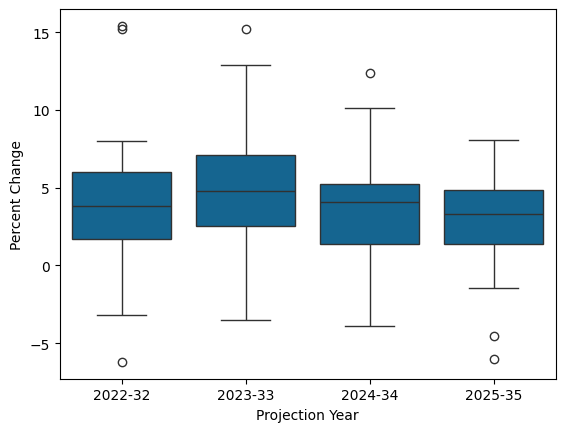

In [ ]:
# comparing mean percent change in groups across all projections
sns.boxplot(comp_years, x= 'Projection Year', y = 'Percent Change', order = ['2022-32', '2023-33', '2024-34', '2025-35'])
plt.show()

In [ ]:
# No significant difference in the mean percent change from the different projections

years_change = ols('Q("Percent Change") ~ Q("Projection Year")', data=comp_years).fit()
years_table = sm.stats.anova_lm(years_change)
print(years_table)

                        df       sum_sq    mean_sq        F    PR(>F)
Q("Projection Year")   3.0    49.157312  16.385771  0.88229  0.453597
Residual              87.0  1615.751659  18.571858      NaN       NaN


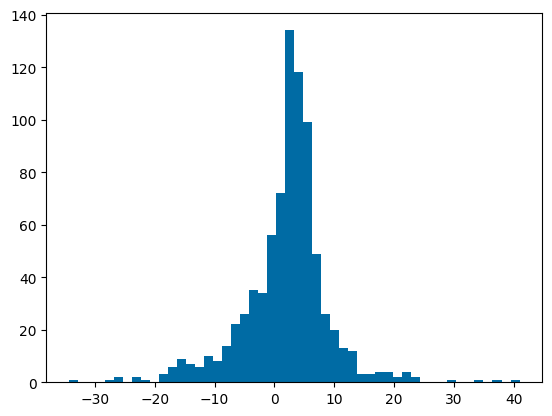

In [ ]:
plt.hist(x=ai_jobs['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [ ]:
ai_jobs['Percent self-employed, 2025'] = ai_jobs['Percent self-employed, 2025'].apply(lambda x: str(x).replace(',', ''))
ai_jobs['Percent self-employed, 2025'] = ai_jobs['Percent self-employed, 2025'].apply(lambda x: str(x).replace('—', ''))
ai_jobs['Percent self-employed, 2025'] = ai_jobs[ai_jobs['Percent self-employed, 2025'] != '']['Percent self-employed, 2025'].apply(lambda x: float(x))

In [ ]:
self_nona = ai_jobs
self_nona['Percent self-employed, 2025'] = self_nona['Percent self-employed, 2025'].dropna()

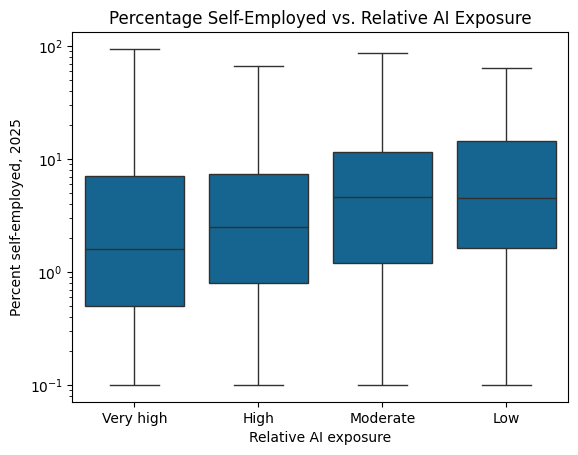

In [ ]:
#What is the relationship between percentage of workers who are self employed and relative AI exposure?

sns.boxplot(ai_jobs, x= 'Relative AI exposure', y = 'Percent self-employed, 2025', log_scale = True)
plt.title('Percentage Self-Employed vs. Relative AI Exposure')
plt.xlabel('Relative AI exposure')
plt.ylabel('Percent self-employed, 2025')

plt.show()

In [ ]:
# No significant relationship between exposure category and percent self-employed

self_ai = ols('Q("Percent self-employed, 2025") ~ Q("Relative AI exposure")', data=ai_jobs).fit()
self_ai_table = sm.stats.anova_lm(self_ai)
print(self_ai_table)

                              df         sum_sq     mean_sq         F  \
Q("Relative AI exposure")    3.0    1555.874190  518.624730  2.176203   
Residual                   612.0  145849.603586  238.316346       NaN   

                             PR(>F)  
Q("Relative AI exposure")  0.089689  
Residual                        NaN  


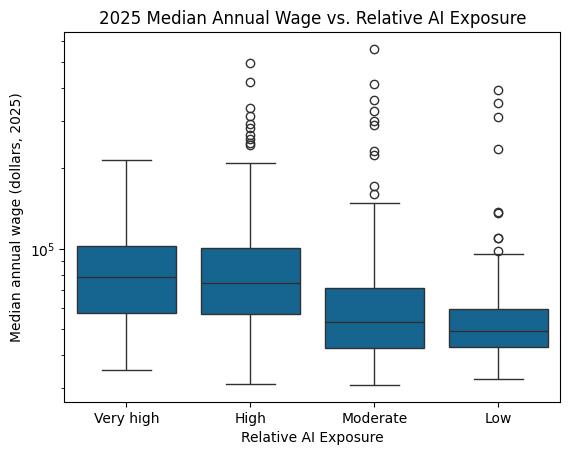

In [ ]:
#What is the relationship between median annual wage and relative AI exposure?

sns.boxplot(ai_jobs, x= 'Relative AI exposure', y = 'Median annual wage, dollars, 2025', log_scale = True)
plt.title('2025 Median Annual Wage vs. Relative AI Exposure')
plt.xlabel('Relative AI Exposure')
plt.ylabel('Median annual wage (dollars, 2025)')

plt.show()

In [ ]:
# Highly significant difference in median annual wage based on AI exposure categories,
# Such that higher exposure is correlated with higher wage

wage_ai = ols('Q("Median annual wage, dollars, 2025") ~ Q("Relative AI exposure")', data=ai_jobs).fit()
wage_ai_table = sm.stats.anova_lm(wage_ai)
print(wage_ai_table)

                              df        sum_sq       mean_sq          F  \
Q("Relative AI exposure")    3.0  1.271164e+11  4.237213e+10  15.993057   
Residual                   808.0  2.140721e+12  2.649408e+09        NaN   

                                 PR(>F)  
Q("Relative AI exposure")  4.151118e-10  
Residual                            NaN  


In [ ]:
sp.posthoc_ttest(ai_jobs, val_col='Median annual wage, dollars, 2025', group_col='Relative AI exposure', p_adjust='holm')

,Very high,High,Moderate,Low
Very high,1.000000e+00,1.508771e-01,0.024275,1.089883e-10
High,1.508771e-01,1.000000e+00,0.005255,6.504997e-09
Moderate,2.427532e-02,5.255226e-03,1.000000,4.460889e-02
Low,1.089883e-10,6.504997e-09,0.044609,1.000000e+00


In [ ]:
ai_jobs['Employment change, percent, 2025–35'].mean()

np.float64(2.030049261083744)

In [ ]:
ai_jobs['Employment change, percent, 2025–35'].median()

2.7

In [ ]:
wage_median = np.median(ai_jobs['Median annual wage, dollars, 2025'])

In [ ]:
wage_diff = ai_jobs
wage_diff.loc[ai_jobs['Median annual wage, dollars, 2025'] >= wage_median, 'Wage Category'] = "High"
wage_diff.loc[ai_jobs['Median annual wage, dollars, 2025'] < wage_median, 'Wage Category'] = "Low"

In [ ]:
low_wage = wage_diff[wage_diff['Wage Category'] == 'Low']
high_wage = wage_diff[wage_diff['Wage Category'] == 'High']

In [ ]:
len(low_wage), len(high_wage)

(406, 406)

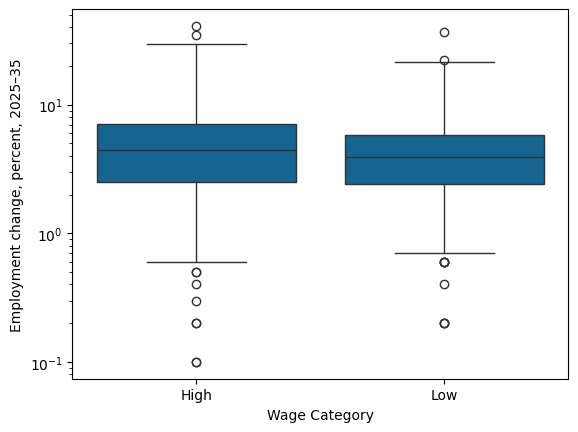

In [ ]:
sns.boxplot(wage_diff, x= 'Wage Category', y = 'Employment change, percent, 2025–35', log_scale = True)
plt.show()

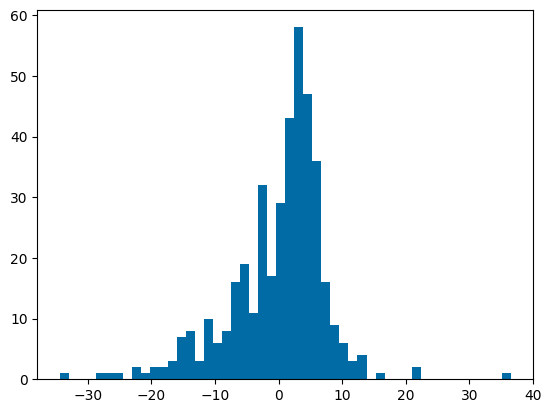

In [ ]:
plt.hist(x=low_wage['Employment change, percent, 2025–35'], bins = 50)
plt.show()

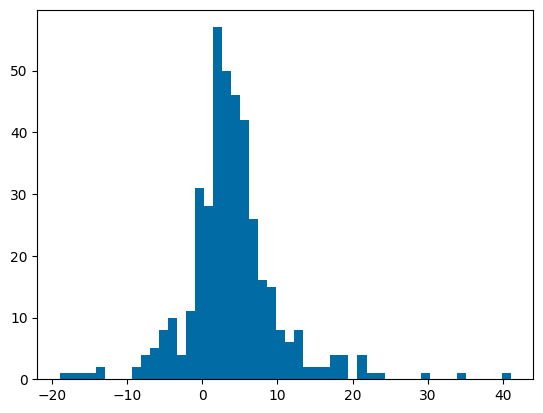

In [ ]:
plt.hist(x=high_wage['Employment change, percent, 2025–35'], bins = 50)
plt.show()

In [ ]:
np.median(low_wage['Employment change, percent, 2025–35']), np.median(high_wage['Employment change, percent, 2025–35'])

(np.float64(1.95), np.float64(3.6500000000000004))

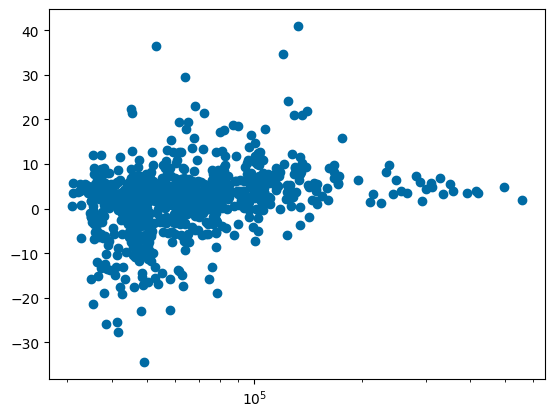

In [ ]:
plt.scatter(x=ai_jobs['Median annual wage, dollars, 2025'], y= ai_jobs['Employment change, percent, 2025–35'])
plt.xscale('log')
plt.show()

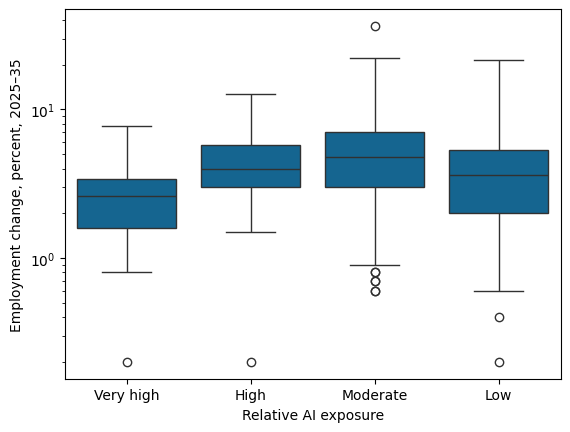

In [ ]:
sns.boxplot(low_wage, x= 'Relative AI exposure',
            y = 'Employment change, percent, 2025–35',
            log_scale = True, order = ['Very high', 'High', 'Moderate', 'Low'])
plt.show()

In [ ]:
low_wage_ai = ols('Q("Median annual wage, dollars, 2025") ~ Q("Relative AI exposure")', data=low_wage).fit()
low_wage_table = sm.stats.anova_lm(low_wage_ai)
print(low_wage_table)

                              df        sum_sq       mean_sq         F  \
Q("Relative AI exposure")    3.0  3.311485e+08  1.103828e+08  1.873929   
Residual                   402.0  2.367960e+10  5.890448e+07       NaN   

                             PR(>F)  
Q("Relative AI exposure")  0.133367  
Residual                        NaN  


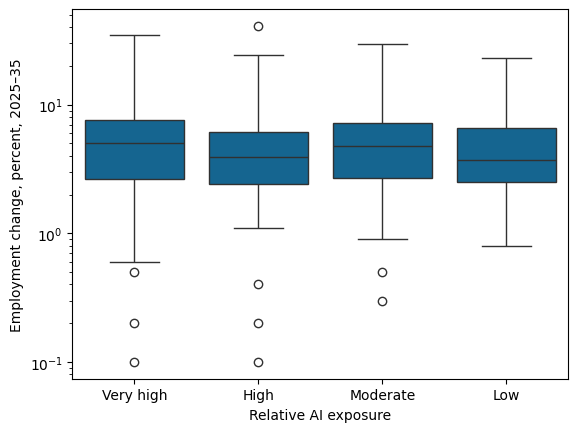

In [ ]:
sns.boxplot(high_wage, x= 'Relative AI exposure',
            y = 'Employment change, percent, 2025–35',
            log_scale = True, order = ['Very high', 'High', 'Moderate', 'Low'])
plt.show()

**K-Means Clustering**

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
scaler = StandardScaler()

In [ ]:
ai_exposure_mapping = {
    'Low':0,
    'Moderate':1,
    'High':2,
    'Very high':3
}

ai_jobs['Relative AI Exposure(num)'] = ai_jobs['Relative AI exposure'].map(ai_exposure_mapping)

In [ ]:
ai_jobs[[
    'Median annual wage, dollars, 2025',
    'Employment change, percent, 2025–35',
    'Occupational openings, 2025–35, annual average',
    'Relative AI Exposure(num)']] = scaler.fit_transform(ai_jobs[[
        'Median annual wage, dollars, 2025',
        'Employment change, percent, 2025–35',
        'Occupational openings, 2025–35, annual average',
        'Relative AI Exposure(num)']])

In [ ]:
kmeans = KMeans(n_clusters = 4)

In [ ]:
kmeans.fit(ai_jobs[[
    'Median annual wage, dollars, 2025',
    'Employment change, percent, 2025–35']])

KMeans(n_clusters=4)

In [ ]:
ai_jobs['kmeans_4'] = kmeans.labels_

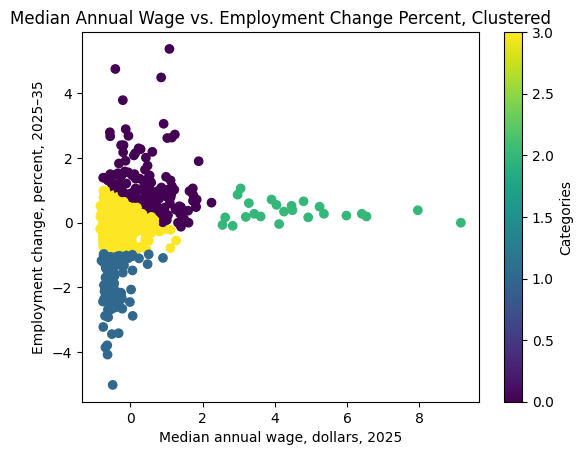

In [ ]:
# Far-right category - after a certain wage threshold you are safe from uncertainty

plt.scatter(
    x=ai_jobs['Median annual wage, dollars, 2025'], y=ai_jobs['Employment change, percent, 2025–35'], c=ai_jobs['kmeans_4'])
plt.title('Median Annual Wage vs. Employment Change Percent, Clustered')
plt.xlabel('Median annual wage, dollars, 2025')
plt.ylabel('Employment change, percent, 2025–35')
plt.colorbar(label="Categories")
plt.show()

In [ ]:
len(ai_jobs[ai_jobs['kmeans_4'] == 0][15:75])

60

In [ ]:
len(ai_jobs[ai_jobs['kmeans_4'] == 1][15:75])

60

In [ ]:
len(ai_jobs[ai_jobs['kmeans_4'] == 2])

24

In [ ]:
len(ai_jobs[ai_jobs['kmeans_4'] == 3])

507

In [ ]:
# Lower wage, decrease in employment.
# Primarily physical labor and clerical work. This is also the largest cluster.

ai_jobs[ai_jobs['kmeans_4'] == 3][15:75]

,Occupation,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Typical education,Related work experience,Typical on-the-job training,Relative AI exposure,Major Group,Wage Category,Relative AI Exposure(num),kmeans_4
40,Compliance officers,436.4,453.1,16.7,0.243601,0.7,0.229590,0.102350,Bachelor's degree,None,Moderate-term on-the-job training,Very high,Business and Financial Operations,High,1.342008,3
41,Cost estimators,226.4,219.5,-6.9,-0.706055,1.3,-0.038801,0.064695,Bachelor's degree,None,Moderate-term on-the-job training,High,Business and Financial Operations,High,0.455344,3
42,Human resources specialists,939.7,999.7,60.1,0.601442,1.1,0.958333,0.011712,Bachelor's degree,None,None,Very high,Business and Financial Operations,High,1.342008,3
43,Farm labor contractors,1.9,2.0,0.1,0.739073,NaN,-0.349850,-0.319048,No formal educational credential,Less than 5 years,Short-term on-the-job training,Low,Business and Financial Operations,Low,-1.317985,3
44,Labor relations specialists,66.3,67.7,1.4,0.009627,1.2,-0.266311,0.380317,Bachelor's degree,Less than 5 years,None,High,Business and Financial Operations,High,0.455344,3
48,"Meeting, convention, and event planners",172.1,182.1,10.0,0.518863,10.1,-0.053021,-0.267958,Bachelor's degree,None,None,High,Business and Financial Operations,Low,0.455344,3
49,Fundraisers,140.9,148.7,7.8,0.477574,0.5,-0.173885,-0.052434,Bachelor's degree,None,None,High,Business and Financial Operations,High,0.455344,3
50,"Compensation, benefits, and job analysis speci...",118.1,125.2,7.1,0.546389,NaN,-0.191660,0.054666,Bachelor's degree,Less than 5 years,None,Very high,Business and Financial Operations,High,1.342008,3
53,"Business operations specialists, all other",1157.6,1202.3,44.7,0.257364,1.9,1.402689,0.146249,Bachelor's degree,None,None,Very high,Business and Financial Operations,High,1.342008,3
54,Accountants and auditors,1595.2,1674.6,79.4,0.408758,5.5,1.697741,0.158170,Bachelor's degree,None,None,Very high,Business and Financial Operations,High,1.342008,3


In [ ]:
# Highest wage, little change in employment.
# Consists solely of CEO's, pilots, and healthcare workers. This is the smallest
# cluster.

ai_jobs[ai_jobs['kmeans_4'] == 2]

,Occupation,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Typical education,Related work experience,Typical on-the-job training,Relative AI exposure,Major Group,Wage Category,Relative AI Exposure(num),kmeans_4
0,Chief executives,291.6,300.9,9.3,0.161022,26.6,-0.012140,2.623924,Bachelor's degree,5 years or more,None,Very high,Management,High,1.342008,2
296,Oral and maxillofacial surgeons,5.6,5.9,0.3,0.491337,12.3,-0.348073,5.239543,Doctoral or professional degree,None,Internship/residency,Low,Healthcare Practitioners and Technical,High,-1.317985,2
297,Orthodontists,7.1,7.5,0.4,0.546389,12.6,-0.348073,4.045929,Doctoral or professional degree,None,Internship/residency,Moderate,Healthcare Practitioners and Technical,High,-0.431321,2
298,Prosthodontists,1.0,1.1,0.1,0.518863,12.6,-0.351628,4.462975,Doctoral or professional degree,None,Internship/residency,Low,Healthcare Practitioners and Technical,High,-1.317985,2
299,"Dentists, all other specialists",5.8,5.9,0.1,-0.100478,7.0,-0.349850,2.832069,Doctoral or professional degree,None,Internship/residency,Moderate,Healthcare Practitioners and Technical,High,-0.431321,2
315,Nurse anesthetists,54.5,59.8,5.3,1.055625,2.8,-0.308970,3.051567,Master's degree,None,None,Low,Healthcare Practitioners and Technical,High,-1.317985,2
319,Anesthesiologists,41.5,43.0,1.5,0.216074,3.9,-0.332076,5.982618,Doctoral or professional degree,None,Internship/residency,Low,Healthcare Practitioners and Technical,High,-1.317985,2
320,Cardiologists,18.5,19.4,0.9,0.381232,3.8,-0.342741,7.960368,Doctoral or professional degree,None,Internship/residency,High,Healthcare Practitioners and Technical,High,0.455344,2
321,Dermatologists,12.2,13.0,0.8,0.656494,4.0,-0.344518,4.795060,Doctoral or professional degree,None,Internship/residency,Moderate,Healthcare Practitioners and Technical,High,-0.431321,2
322,Emergency medicine physicians,34.9,36.1,1.1,0.161022,3.7,-0.335631,4.924109,Doctoral or professional degree,None,Internship/residency,High,Healthcare Practitioners and Technical,High,0.455344,2


In [ ]:
# Low to medium wage and increase in employment.
# Primarily specialized jobs, managers, scientists, engineers

ai_jobs[ai_jobs['kmeans_4'] == 1][15:75]

,Occupation,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Typical education,Related work experience,Typical on-the-job training,Relative AI exposure,Major Group,Wage Category,Relative AI Exposure(num),kmeans_4
400,Transportation security screeners,53.5,51.2,-2.2,-0.857450,NaN,-0.271644,-0.161804,High school diploma or equivalent,None,Short-term on-the-job training,Moderate,Protective Service,High,-0.431321,1
409,"Cooks, short order",138.7,131.5,-7.2,-0.995081,NaN,-0.042356,-0.746312,No formal educational credential,None,Short-term on-the-job training,Low,Food Preparation and Serving Related,Low,-1.317985,1
438,Motion picture projectionists,1.5,1.4,-0.1,-1.132712,NaN,-0.346295,-0.701087,No formal educational credential,None,Short-term on-the-job training,Low,Personal Care and Service,Low,-1.317985,1
463,Cashiers,3106.3,2905.7,-200.6,-1.174002,0.4,8.914079,-0.803078,No formal educational credential,None,Short-term on-the-job training,High,Sales and Related,Low,0.455344,1
468,Advertising sales agents,99.3,92.2,-7.1,-1.270343,7.7,-0.212989,-0.198703,High school diploma or equivalent,None,Moderate-term on-the-job training,Very high,Sales and Related,High,1.342008,1
480,Telemarketers,60.9,47.8,-13.0,-3.224708,2.9,-0.248537,-0.754448,No formal educational credential,None,Short-term on-the-job training,Very high,Sales and Related,Low,1.342008,1
481,"Door-to-door sales workers, news and street ve...",50.9,45.6,-5.3,-1.710764,94.6,-0.266311,-0.642239,No formal educational credential,None,Short-term on-the-job training,Very high,Sales and Related,Low,1.342008,1
484,"Switchboard operators, including answering ser...",35.4,26.2,-9.2,-3.857812,1.6,-0.296528,-0.694275,High school diploma or equivalent,None,Short-term on-the-job training,Very high,Office and Administrative Support,Low,1.342008,1
485,Telephone operators,3.5,2.5,-1.0,-4.078022,NaN,-0.348073,-0.635427,High school diploma or equivalent,None,Short-term on-the-job training,High,Office and Administrative Support,Low,0.455344,1
487,Bill and account collectors,160.2,143.4,-16.7,-1.710764,0.3,-0.152556,-0.535329,High school diploma or equivalent,None,Moderate-term on-the-job training,Very high,Office and Administrative Support,Low,1.342008,1


In [ ]:
# Low to medium wage and variability in employment.
# Similar to previous cluster, specialized jobs including engineers,
# accountants, but more humanities-based occupations.

ai_jobs[ai_jobs['kmeans_4'] == 0][15:75]

,Occupation,"Employment, 2025","Employment, 2035","Employment change, numeric, 2025–35","Employment change, percent, 2025–35","Percent self-employed, 2025","Occupational openings, 2025–35, annual average","Median annual wage, dollars, 2025",Typical education,Related work experience,Typical on-the-job training,Relative AI exposure,Major Group,Wage Category,Relative AI Exposure(num),kmeans_4
18,Construction managers,609.1,664.3,55.2,0.973046,37.6,0.531752,0.750625,Bachelor's degree,None,Moderate-term on-the-job training,High,Management,High,0.455344,0
23,Architectural and engineering managers,220.9,233.1,12.2,0.477574,0.2,-0.086792,1.815567,Bachelor's degree,5 years or more,None,High,Management,High,0.455344,0
28,Medical and health services managers,640.4,795.5,155.1,3.051279,4.5,0.755707,0.918465,Bachelor's degree,Less than 5 years,None,High,Management,High,0.455344,0
29,Natural sciences managers,112.2,121.5,9.2,0.849178,NaN,-0.188105,1.738932,Bachelor's degree,5 years or more,None,High,Management,High,0.455344,0
32,Social and community service managers,231.0,247.7,16.6,0.711547,4.8,-0.022804,0.095916,Bachelor's degree,Less than 5 years,None,Very high,Management,High,1.342008,0
36,"Managers, all other",1338.8,1404.4,65.6,0.394995,50.4,1.441792,1.259822,Bachelor's degree,Less than 5 years,None,High,Management,High,0.455344,0
37,"Agents and business managers of artists, perfo...",26.9,29.5,2.6,1.055625,45.4,-0.308970,0.143222,Bachelor's degree,Less than 5 years,None,Very high,Business and Financial Operations,High,1.342008,0
45,Logisticians,255.1,300.0,44.9,2.142912,1.2,0.121167,0.132436,Bachelor's degree,None,None,Very high,Business and Financial Operations,High,1.342008,0
46,Project management specialists,1094.3,1167.4,73.2,0.642731,1.2,1.008101,0.510881,Bachelor's degree,None,None,Very high,Business and Financial Operations,High,1.342008,0
47,Management analysts,1077.1,1186.3,109.2,1.110678,14.0,1.320927,0.502176,Bachelor's degree,Less than 5 years,None,Very high,Business and Financial Operations,High,1.342008,0


In [ ]:
kmeans.fit(ai_jobs[[
    'Median annual wage, dollars, 2025',
    'Occupational openings, 2025–35, annual average']])

KMeans(n_clusters=4)

In [ ]:
ai_jobs['kmeans_4'] = kmeans.labels_

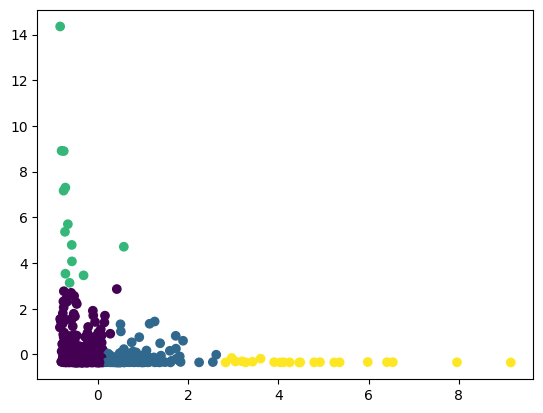

In [ ]:
# Similarly, limited growth past a certain wage

plt.scatter(
    x=ai_jobs['Median annual wage, dollars, 2025'], y=ai_jobs[
        'Occupational openings, 2025–35, annual average'], c=ai_jobs['kmeans_4'])
plt.show()

In [ ]:
kmeans.fit(ai_jobs[[
    'Median annual wage, dollars, 2025',
    'Relative AI Exposure(num)']])

KMeans(n_clusters=4)

In [ ]:
ai_jobs['kmeans_4'] = kmeans.labels_

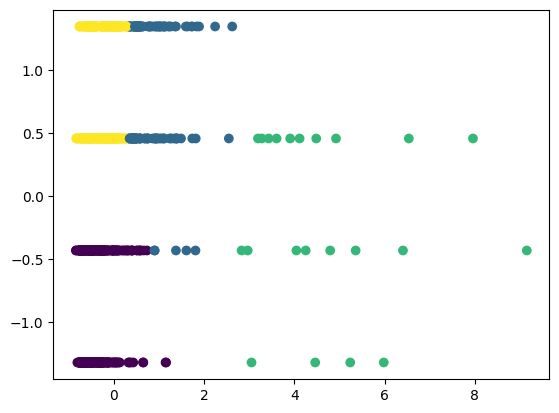

In [ ]:
# Again there is a green category where, past a certain wage, one is safe from
# very high AI exposure
plt.scatter(
    x=ai_jobs['Median annual wage, dollars, 2025'], y=ai_jobs[
        'Relative AI Exposure(num)'], c=ai_jobs['kmeans_4'])
plt.show()

In [ ]:
kmeans.fit(ai_jobs[[
    'Employment change, percent, 2025–35',
    'Relative AI Exposure(num)']])
ai_jobs['kmeans_4'] = kmeans.labels_

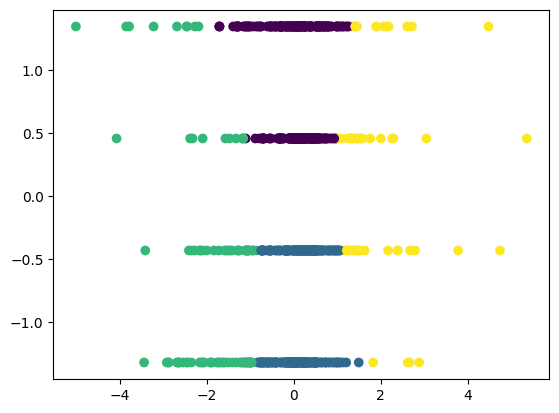

In [ ]:
# This one does not show any qualitative clusters, simply jobs with higher/lower
# percent change and higher/lower exposure
plt.scatter(
    x=ai_jobs['Employment change, percent, 2025–35'], y=ai_jobs[
        'Relative AI Exposure(num)'], c=ai_jobs['kmeans_4'])
plt.show()

Our goal with these regressions is to follow up on our EDA plots and investigate the significance of any relationships between demographics and earnings/AI exposure.

In [ ]:
jobs_demographic.columns


Index(['Occupation', '2025 National Employment Matrix code',
       'Employment, 2025', 'Employment, 2035',
       'Employment change, numeric, 2025–35',
       'Employment change, percent, 2025–35', 'Percent self-employed, 2025',
       'Occupational openings, 2025–35, annual average',
       'Median annual wage, dollars, 2025', 'Typical education',
       'Related work experience', 'Typical on-the-job training',
       'Relative AI exposure', 'Total Employed', 'Women', 'White',
       'Black or African American', 'Asian', 'Hispanic or Latino',
       'Major Group'],
      dtype='object')

In [ ]:
#Have to turn categorical variables into numerical indicators
#starting at 0 instead of 1 gives the intercept a "meaningful interpretation"
jobs_dem_num = jobs_demographic.copy()
education_mapping = {
    'No formal educational credential': 0,
    'High school diploma or equivalent': 1,
    'Some college, no degree': 2,
    'Associate\'s degree': 3,
    'Postsecondary nondegree award': 4,  # <-- Added missing category
    'Bachelor\'s degree': 5,
    'Master\'s degree': 6,
    'Doctoral or professional degree': 7
}

training_mapping = {
    'None': 0,                           # <-- Added missing category
    'Short-term on-the-job training': 1,
    'Moderate-term on-the-job training': 2,
    'Long-term on-the-job training': 3,
    'Apprenticeship': 4,
    'Internship/residency': 5,
}

related_work_mapping = {
    'None': 0,
    'Less than 5 years': 1,
    '5 years or more': 2
}
ai_exposure_mapping = {
    'Low':0,
    'Moderate':1,
    'High':2,
    'Very high':3
}

jobs_dem_num['Typical education (num)'] = jobs_dem_num['Typical education'].map(education_mapping)
jobs_dem_num['Related work experience (num)'] = jobs_dem_num['Related work experience'].map(related_work_mapping)
jobs_dem_num['Typical on-the-job training (num)'] = jobs_dem_num['Typical on-the-job training'].map(training_mapping)
jobs_dem_num['Relative AI exposure (num)'] = jobs_dem_num['Relative AI exposure'].map(ai_exposure_mapping)

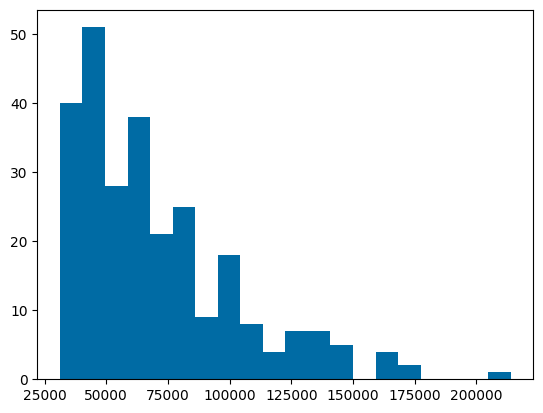

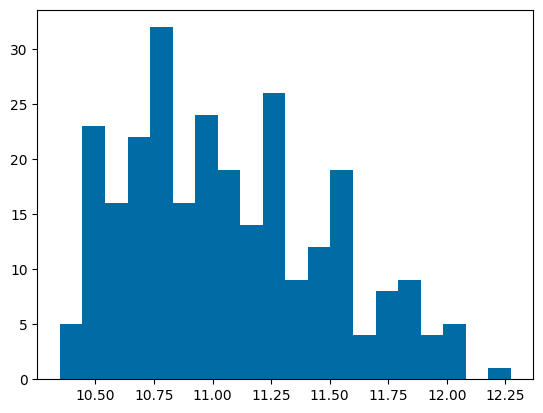

In [ ]:
jobs_dem_num['Log Median annual wage, dollars, 2025'] = np.log(jobs_dem_num['Median annual wage, dollars, 2025'])

plt.hist(jobs_dem_num['Median annual wage, dollars, 2025'], bins=20)
plt.show()

plt.hist(jobs_dem_num['Log Median annual wage, dollars, 2025'], bins=20)
plt.show()



Are certain demographic makeups associated with higher or lower median wages (controlling for required education, typical work experience, and on the job training)?

Dependent variable: Median annual wage, dollars, 2025

Independent variables:
- Demographic percentages (racial groups and gender)
- On the job training, education, typical work experience

In [ ]:
#leave out white for "meaningful intercept"
dem_wage_model_categ = smf.ols('Q("Log Median annual wage, dollars, 2025") ~  C(Q("Typical education (num)")) + C(Q("Related work experience (num)")) + C(Q("Typical on-the-job training (num)")) + Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")', data=jobs_dem_num).fit()
print(dem_wage_model_categ.summary())

                                        OLS Regression Results                                        
Dep. Variable:     Q("Log Median annual wage, dollars, 2025")   R-squared:                       0.786
Model:                                                    OLS   Adj. R-squared:                  0.771
Method:                                         Least Squares   F-statistic:                     50.86
Date:                                        Sat, 14 Nov 2026   Prob (F-statistic):           1.11e-72
Time:                                                04:30:23   Log-Likelihood:                 58.690
No. Observations:                                         268   AIC:                            -79.38
Df Residuals:                                             249   BIC:                            -11.15
Df Model:                                                  18                                         
Covariance Type:                                    nonrobust            

In [ ]:
#treating ordinal categorical variables as continuous quantitative
#omit white for meaningful intercept
#includes control factors!
dem_wage_model_quant = smf.ols('Q("Log Median annual wage, dollars, 2025") ~ Q("Typical education (num)") + Q("Related work experience (num)") + Q("Typical on-the-job training (num)") + Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")', data=jobs_dem_num).fit()
print(dem_wage_model_quant.summary())

#multicollinearity in control predictors, but that's okay because we are interested in demographic significance
#also, treating ordinal categorical variables as continuous quantitative preserves inherent hierarchy
#also, treating them as categorical threw a SingularMatrixWarning

                                        OLS Regression Results                                        
Dep. Variable:     Q("Log Median annual wage, dollars, 2025")   R-squared:                       0.724
Model:                                                    OLS   Adj. R-squared:                  0.716
Method:                                         Least Squares   F-statistic:                     97.23
Date:                                        Sat, 14 Nov 2026   Prob (F-statistic):           6.82e-69
Time:                                                04:30:24   Log-Likelihood:                 24.291
No. Observations:                                         268   AIC:                            -32.58
Df Residuals:                                             260   BIC:                            -3.855
Df Model:                                                   7                                         
Covariance Type:                                    nonrobust            

Is there a relationship between racial demographics and typical education? OTJ training? Typical work experience?

In [ ]:

# typical education
model_edu = smf.ols(
    'Q("Typical education (num)") ~ Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")',
    data=jobs_dem_num
).fit()
print(model_edu.summary())


# related work experience
model_exp = smf.ols(
    'Q("Related work experience (num)") ~ Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")',
    data=jobs_dem_num
).fit()
print(model_exp.summary())


# on-the-job training
model_train = smf.ols(
    'Q("Typical on-the-job training (num)") ~ Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")',
    data=jobs_dem_num
).fit()
print(model_train.summary())

                                 OLS Regression Results                                 
Dep. Variable:     Q("Typical education (num)")   R-squared:                       0.368
Model:                                      OLS   Adj. R-squared:                  0.359
Method:                           Least Squares   F-statistic:                     38.34
Date:                          Sat, 14 Nov 2026   Prob (F-statistic):           2.87e-25
Time:                                  04:30:24   Log-Likelihood:                -520.12
No. Observations:                           268   AIC:                             1050.
Df Residuals:                               263   BIC:                             1068.
Df Model:                                     4                                         
Covariance Type:                      nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------

Without controlling for job similarities, just looking at demographic distributions, how are different racial/gender makeups correlated with wage?

Answer: each has highly significant relationship

In [ ]:
#without including those control factors, every demographic variable is highly significant
dem_wage_model_justdem = smf.ols('Q("Median annual wage, dollars, 2025") ~ Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")', data=jobs_dem_num).fit()
print(dem_wage_model_justdem.summary())

                                      OLS Regression Results                                      
Dep. Variable:     Q("Median annual wage, dollars, 2025")   R-squared:                       0.399
Model:                                                OLS   Adj. R-squared:                  0.390
Method:                                     Least Squares   F-statistic:                     43.61
Date:                                    Sat, 14 Nov 2026   Prob (F-statistic):           4.71e-28
Time:                                            04:30:24   Log-Likelihood:                -3098.1
No. Observations:                                     268   AIC:                             6206.
Df Residuals:                                         263   BIC:                             6224.
Df Model:                                               4                                         
Covariance Type:                                nonrobust                                         
          

Are occupations with specific demographic makeups predicted to grow faster from 2025 to 2035, controlling for typical education, related work experience, and typical OTJ training? (Dependent: Employment change, percent, 2025-35)

In [ ]:
#Employment change, percent, 2025-35
dem_emp_change_controls_model = smf.ols('Q("Employment change, percent, 2025–35") ~ Q("Typical education (num)") + Q("Related work experience (num)") + Q("Typical on-the-job training (num)") + Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")', data=jobs_dem_num).fit()
print(dem_emp_change_controls_model.summary())

                                       OLS Regression Results                                       
Dep. Variable:     Q("Employment change, percent, 2025–35")   R-squared:                       0.163
Model:                                                  OLS   Adj. R-squared:                  0.141
Method:                                       Least Squares   F-statistic:                     7.258
Date:                                      Sat, 14 Nov 2026   Prob (F-statistic):           5.98e-08
Time:                                              04:31:22   Log-Likelihood:                -878.83
No. Observations:                                       268   AIC:                             1774.
Df Residuals:                                           260   BIC:                             1802.
Df Model:                                                 7                                         
Covariance Type:                                  nonrobust                                

Are occupations with specific demographic makeups predicted to grow faster from 2025 to 2035, without controlling for typical education, related work experience, and typical OTJ training? (Dependent: Employment change, percent, 2025-35)

In [ ]:
dem_emp_change_model = smf.ols('Q("Employment change, percent, 2025–35") ~ Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")', data=jobs_dem_num).fit()
print(dem_emp_change_model.summary())

                                       OLS Regression Results                                       
Dep. Variable:     Q("Employment change, percent, 2025–35")   R-squared:                       0.051
Model:                                                  OLS   Adj. R-squared:                  0.037
Method:                                       Least Squares   F-statistic:                     3.561
Date:                                      Sat, 14 Nov 2026   Prob (F-statistic):            0.00754
Time:                                              04:31:32   Log-Likelihood:                -895.68
No. Observations:                                       268   AIC:                             1801.
Df Residuals:                                           263   BIC:                             1819.
Df Model:                                                 4                                         
Covariance Type:                                  nonrobust                                

Are certain demographic groups more concentrated in occupations predicted to have high AI exposure, controlling for typical education, related work experience, and typical OTJ training??

In [ ]:
dem_AI_controls_model = smf.ols('Q("Relative AI exposure (num)") ~ Q("Typical education (num)") + Q("Related work experience (num)") + Q("Typical on-the-job training (num)") + Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")', data=jobs_dem_num).fit()
print(dem_AI_controls_model.summary())

                                   OLS Regression Results                                  
Dep. Variable:     Q("Relative AI exposure (num)")   R-squared:                       0.290
Model:                                         OLS   Adj. R-squared:                  0.271
Method:                              Least Squares   F-statistic:                     15.16
Date:                             Sat, 14 Nov 2026   Prob (F-statistic):           1.36e-16
Time:                                     04:31:32   Log-Likelihood:                -362.08
No. Observations:                              268   AIC:                             740.2
Df Residuals:                                  260   BIC:                             768.9
Df Model:                                        7                                         
Covariance Type:                         nonrobust                                         
                                             coef    std err          t      P>|

Are certain demographic groups more concentrated in occupations predicted to have high AI exposure, without controlling for typical education, related work experience, and typical OTJ training??

In [ ]:
dem_AI_model = smf.ols('Q("Relative AI exposure (num)") ~ Q("Women") + Q("Black or African American") + Q("Asian") + Q("Hispanic or Latino")', data=jobs_dem_num).fit()
print(dem_AI_model.summary())

                                   OLS Regression Results                                  
Dep. Variable:     Q("Relative AI exposure (num)")   R-squared:                       0.274
Model:                                         OLS   Adj. R-squared:                  0.263
Method:                              Least Squares   F-statistic:                     24.78
Date:                             Sat, 14 Nov 2026   Prob (F-statistic):           2.02e-17
Time:                                     04:31:32   Log-Likelihood:                -365.09
No. Observations:                              268   AIC:                             740.2
Df Residuals:                                  263   BIC:                             758.1
Df Model:                                        4                                         
Covariance Type:                         nonrobust                                         
                                     coef    std err          t      P>|t|      

Is there a significant relationship between projected employment change and relative AI exposure?

In [ ]:
dem_AI_empchange_model = smf.ols('Q("Employment change, percent, 2025–35") ~ Q("Relative AI exposure (num)")', data=jobs_dem_num).fit()
print(dem_AI_empchange_model.summary())

                                       OLS Regression Results                                       
Dep. Variable:     Q("Employment change, percent, 2025–35")   R-squared:                       0.012
Model:                                                  OLS   Adj. R-squared:                  0.008
Method:                                       Least Squares   F-statistic:                     3.220
Date:                                      Sat, 14 Nov 2026   Prob (F-statistic):             0.0739
Time:                                              04:31:40   Log-Likelihood:                -901.14
No. Observations:                                       268   AIC:                             1806.
Df Residuals:                                           266   BIC:                             1813.
Df Model:                                                 1                                         
Covariance Type:                                  nonrobust                                